# Exploratory Data Analysis — Virtue Foundation India Healthcare Facilities

**Challenge:** given a *service* (dialysis, C-section, NICU, MRI…) and a *location*, recommend the best facility **with evidence**, and communicate uncertainty.

This notebook profiles **all three files** in `Dataset/`:

| File | What it is | Role in the build |
|---|---|---|
| `facilities.csv` | ~10k facilities, 51 attributes, extracted from web text | The core dataset – every field is a *claim* |
| `india_post_pincode_directory.csv` | India Post offices with PIN, district, state, lat/long | Ground truth for geocoding PIN → district/state/centroid; validating facility locations |
| `nfhs_5_district_health_indicators.csv` | NFHS‑5 (2019‑21) district health indicators | Demand / need context per district (e.g. C‑section rates, institutional births, insurance) |

**Sections**
1. Setup & robust loading (the CSV is malformed – see §1)
2. File integrity: broken rows & truncated records
3. Schema / data dictionary & data types
4. Hidden null tokens & missingness (incl. nullity correlation)
5. Constant / useless columns
6. Categorical fields
7. Nested list fields (specialties, procedure, equipment, capability…)
8. Location: states, cities, PIN codes, coordinates
9. Numeric fields: distributions, outliers, implausible values, correlations
10. Dates, social media & engagement
11. Contact info & provenance (source URLs)
12. Free‑text description
13. Duplicates & merged/contradictory records (trust issues)
14. Service‑claim coverage for the challenge services
15. Pincode directory EDA
16. NFHS‑5 EDA
17. Cross‑dataset joins: facility → PIN → district → NFHS
18. Per‑facility completeness / evidence score
19. Key findings & implications for the build

## 0. Setup

In [1]:
import pandas as pd, numpy as np, json, re, warnings
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from urllib.parse import urlparse
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 120); pd.set_option('display.max_rows', 200)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
DATA = 'Dataset'
INDIA_BBOX = dict(lat=(6.0, 37.6), lon=(68.0, 97.5))   # generous mainland + islands bounding box

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def in_india(lat, lon):
    return lat.between(*INDIA_BBOX['lat']) & lon.between(*INDIA_BBOX['lon'])

## 1. Robust loading

`facilities.csv` does **not** use standard CSV quoting: embedded quotes are backslash‑escaped (`\"`) instead of doubled (`""`).
A plain `pd.read_csv` crashes (`Expected 593 fields in line 11, saw 647`). We load with `escapechar='\\'`, and read every column as raw text first (`dtype=str, keep_default_na=False`) so we can see what the *literal* null tokens are before converting anything.

In [2]:
raw_text = open(f'{DATA}/facilities.csv', encoding='utf-8').read()
print(f"File size: {len(raw_text)/1e6:.1f} MB | physical lines: {raw_text.count(chr(10)):,}")
print(f'Backslash-escaped quotes \\": {raw_text.count(chr(92)+chr(34)):,} | doubled quotes "": {raw_text.count(chr(34)*2):,}')

try:
    pd.read_csv(f'{DATA}/facilities.csv', low_memory=False)
except Exception as e:
    print('\nNaive read_csv fails ->', type(e).__name__, ':', str(e)[:120])

raw = pd.read_csv(f'{DATA}/facilities.csv', escapechar='\\', dtype=str, keep_default_na=False, low_memory=False)
print('\nRows parsed with escapechar:', raw.shape)

File size: 74.6 MB | physical lines: 10,089
Backslash-escaped quotes \": 3,437,810 | doubled quotes "": 67

Naive read_csv fails -> ParserError : Error tokenizing data. C error: Expected 593 fields in line 11, saw 647




Rows parsed with escapechar: (10088, 51)


## 2. File integrity – broken rows and truncated records

Some `description` values contained **raw newlines** that were not quoted on export, so the record spilled onto extra lines. Those spill‑over lines become junk "rows" whose `unique_id` is a sentence fragment. A valid record has a UUID in `unique_id`.

In [3]:
UUID = r'[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}'
is_valid = raw['unique_id'].str.fullmatch(UUID)
print(f"Valid UUID rows: {is_valid.sum():,} | junk fragment rows: {(~is_valid).sum():,}")
print('\nExamples of junk rows (the unique_id column actually holds description text):')
display(raw.loc[~is_valid, ['unique_id','source_types','source_ids']].head(8))

fac_raw = raw[is_valid].copy()
dup_id = fac_raw['unique_id'].duplicated(keep=False)
print(f"\nunique_id is NOT unique: {dup_id.sum()} rows share {fac_raw.loc[dup_id,'unique_id'].nunique()} ids")
print('Are those rows exact copies of each other?', fac_raw[dup_id].drop_duplicates().shape[0] == fac_raw.loc[dup_id,'unique_id'].nunique())
display(fac_raw.loc[dup_id, ['unique_id','name','address_city']].sort_values('unique_id').head(6))
fac_raw = fac_raw.drop_duplicates().reset_index(drop=True)
print(f'After dropping exact duplicate rows: {len(fac_raw):,} unique facilities; unique_id unique ->', fac_raw.unique_id.is_unique)

Valid UUID rows: 10,000 | junk fragment rows: 88

Examples of junk rows (the unique_id column actually holds description text):


,unique_id,source_types,source_ids
118,Dr. Gita Khanna has established Ajanta Hospital and IVF Centre a 100 plus bedded multispeciality hospital of Interna...,compassion,integrity
1786,Such a Centre is a very useful facility for the University’s employees as it provides supervision and care for infan...,to enable their parents,especially the mothers
1787,| **Dr. Anvita Verma**,,
1788,Assistant Professor (Social Work),,
1789,Mobile: +91-9451520000,,
1790,Email: verma_anvita@lkouniv.ac.in,,
1791,---|---,,
1792,| **Dr. Aditya Abha Singh**,,



unique_id is NOT unique: 22 rows share 11 ids
Are those rows exact copies of each other? True


,unique_id,name,address_city
106,08344cdb-f455-4c22-8d31-a0a8e849124b,MOSC Medical College Hospital,Kolenchery
107,08344cdb-f455-4c22-8d31-a0a8e849124b,MOSC Medical College Hospital,Kolenchery
3101,1a0f7290-f227-49fe-9b92-a8c698a165d8,Malhotra Super Speciality Hospital,Baddi
3102,1a0f7290-f227-49fe-9b92-a8c698a165d8,Malhotra Super Speciality Hospital,Baddi
4523,277e82f0-241a-458a-b9fc-e32d2b3dfcba,Sabine Hospital and Research Centre,Muvattupuzha
4524,277e82f0-241a-458a-b9fc-e32d2b3dfcba,Sabine Hospital and Research Centre,Muvattupuzha


After dropping exact duplicate rows: 9,989 unique facilities; unique_id unique -> True


In [4]:
# Records that were cut off mid-way: the description broke the line, so every column after it is empty.
desc_pos = list(fac_raw.columns).index('description')
after_desc = fac_raw.columns[desc_pos+1:]
truncated = (fac_raw[after_desc] == '').all(axis=1) | (fac_raw['cluster_id'] == '')
print(f"Truncated records (all columns after `description` empty): {truncated.sum()}")
print('These lose specialties / procedure / equipment / capability / coordinates / source_urls.')
display(fac_raw.loc[truncated, ['name','address_city','address_stateOrRegion','description']].head(10))

Truncated records (all columns after `description` empty): 30
These lose specialties / procedure / equipment / capability / coordinates / source_urls.


,name,address_city,address_stateOrRegion,description
116,Ajanta Hospital & Ivf Centre,Lucknow,Uttar Pradesh,"The mission of Ajanta Hospital & IVF Center, Lucknow is to provide quality health services and facilities for the co..."
1781,Mother And Child Care,Ghaziabad,Uttar Pradesh,The safety and the security of children is always a major concern for working mothers. The University of Lucknow off...
2119,Bharati Fertility Center,Mandaveli,Tamil Nadu,"Bharati Fertility Center is a state-of-the-art facility equipped with the newest technology, capable of handling all..."
2407,Oberoi Hospital,Pathankot,Punjab,Oberoi Hospital
2427,Krishna X-ray,Anand,Gujarat,Krishna X-Ray is one of the advanced and leading radio-diagnostic center in Anand( Gujarat) and this has happened be...
2649,Sri Sai Lions Netralaya,Patna,Bihar,"Sri Sai Lions Netralaya is serving people with eye related diseases since December 12th, 2004. Our main focus is on ..."
2745,"Dhanwantari Hospital Centre for Psychiatric Care, Raipur, Chhattisgarh India",Raipur,Chhattisgarh,"Dhanwantari Hospital Centre for Psychiatric Care, Raipur, Chhattisgarh India is the regional leader in the provision..."
2776,Venkateswara Diagnostic Center,Chennai,Tamil Nadu,The Leader in Diagnostics Scan Centre at Chennai
3478,Choithram Netralaya,Indore,Madhya Pradesh,"A modest name, paving path for itself, by providing world class eye care, is what describes Choithram Netralaya."
3576,Manorama Hospitex,Ranaghat,West Bengal,Manorama Hospitex pvt. ltd. at Ranaghat is an initiative of the Monorama ultrascan pvt. ltd. This 494 bedded Multi-S...


## 3. Schema / data dictionary

In [5]:
# Hidden null tokens: what literal values represent 'missing'?
tokens = ['', 'null', 'NULL', 'None', 'nan', 'NaN', 'N/A', 'NA', '[]', '{}', '[""]']
tok = pd.DataFrame({t: (fac_raw == t).sum() for t in tokens})
tok = tok.loc[:, tok.sum() > 0]
tok = tok[tok.sum(axis=1) > 0]
print('Count of literal null-like tokens per column (raw text):')
display(tok.sort_values(tok.columns.tolist(), ascending=False))

Count of literal null-like tokens per column (raw text):


,,null,NULL,[],"[""""]"
area,30,9834,0,0,0
capacity,30,7449,0,0,0
number_of_facts_about_the_organization,30,7204,0,0,0
recency_of_page_update,30,6421,1,0,0
numberDoctors,30,6331,0,0,0
post_metrics_post_count,30,6185,0,0,0
engagement_metrics_n_engagements,30,5082,0,0,0
post_metrics_most_recent_social_media_post_date,30,5034,0,0,0
engagement_metrics_n_likes,30,2170,0,0,0
engagement_metrics_n_followers,30,1086,0,0,0


Two distinct encodings of "missing": an **empty string** (from the broken/truncated rows and genuinely empty cells) and the literal **`null`**. Separately, list columns can hold **`[]`** – the field exists but the list is empty, which is semantically *"extracted nothing"* and should be treated as missing for evidence purposes.

In [6]:
fac = fac_raw.replace({'': np.nan, 'null': np.nan})

GROUPS = {
 'ID / lineage': ['unique_id','source_content_id','content_table_id','cluster_id','source','source_types','source_ids','organization_type'],
 'Identity':     ['name','facilityTypeId','operatorTypeId','affiliationTypeIds','description'],
 'Contact':      ['phone_numbers','officialPhone','email','websites','officialWebsite','facebookLink','acceptsVolunteers'],
 'Location':     ['address_line1','address_line2','address_line3','address_city','address_stateOrRegion','address_zipOrPostcode',
                  'address_country','address_countryCode','countries','coordinates','latitude','longitude'],
 'Offerings':    ['specialties','procedure','equipment','capability'],
 'Scale/history':['yearEstablished','numberDoctors','capacity','area'],
 'Web/social signals': ['recency_of_page_update','distinct_social_media_presence_count','affiliated_staff_presence','custom_logo_presence',
                  'number_of_facts_about_the_organization','post_metrics_most_recent_social_media_post_date','post_metrics_post_count',
                  'engagement_metrics_n_followers','engagement_metrics_n_likes','engagement_metrics_n_engagements'],
 'Provenance':   ['source_urls'],
}
col2group = {c: g for g, cs in GROUPS.items() for c in cs}
assert set(col2group) == set(fac.columns), set(fac.columns) ^ set(col2group)

LIST_COLS = ['source_types','source_ids','phone_numbers','websites','affiliationTypeIds','specialties','procedure','equipment','capability','source_urls']
NUM_COLS  = ['yearEstablished','numberDoctors','capacity','area','latitude','longitude','distinct_social_media_presence_count',
             'number_of_facts_about_the_organization','post_metrics_post_count','engagement_metrics_n_followers',
             'engagement_metrics_n_likes','engagement_metrics_n_engagements']
DATE_COLS = ['recency_of_page_update','post_metrics_most_recent_social_media_post_date']
BOOL_COLS = ['acceptsVolunteers','affiliated_staff_presence','custom_logo_presence']
JSON_COLS = ['coordinates']
TEXT_COLS = ['description','name','address_line1','address_line2','address_line3']

def semantic(c):
    if c in LIST_COLS: return 'JSON list'
    if c in NUM_COLS: return 'numeric'
    if c in DATE_COLS: return 'date'
    if c in BOOL_COLS: return 'boolean'
    if c in JSON_COLS: return 'GeoJSON'
    if c in TEXT_COLS: return 'free text'
    if c in ['unique_id','source_content_id','content_table_id','cluster_id']: return 'identifier'
    if c in ['email','officialPhone','officialWebsite','facebookLink']: return 'contact string'
    return 'categorical / short string'

dd = pd.DataFrame({
    'group': [col2group[c] for c in fac.columns],
    'semantic_type': [semantic(c) for c in fac.columns],
    'non_null': fac.notna().sum().values,
    'pct_non_null': (fac.notna().mean()*100).round(1).values,
    'n_unique': fac.nunique().values,
    'example': [str(fac[c].dropna().iloc[0])[:70] if fac[c].notna().any() else '' for c in fac.columns],
}, index=fac.columns)
print(f'{fac.shape[0]:,} facilities x {fac.shape[1]} columns')
print(dd.semantic_type.value_counts().to_string())
dd

9,989 facilities x 51 columns
semantic_type
numeric                       12
JSON list                     10
categorical / short string    10
free text                      5
identifier                     4
contact string                 4
boolean                        3
date                           2
GeoJSON                        1


,group,semantic_type,non_null,pct_non_null,n_unique,example
unique_id,ID / lineage,identifier,9989,100.0,9989,b8a5401f-42f1-422a-8cd9-686a15b4cb76
source_types,ID / lineage,JSON list,9961,99.7,6276,"[""dynamic"",""overture"",""constant"",""mongo_facility"",""dynamic"",""overture"""
source_ids,ID / lineage,JSON list,9961,99.7,9232,"[""08f42d99986e2b6d03862b16be6f4556"",""08f3cb3a2a1a139503b31af626a9e452"""
source_content_id,ID / lineage,identifier,9989,100.0,9067,c2ada12b-11f7-45f2-93b6-94f7e8853c7a
name,Identity,free text,9989,100.0,9507,Aravind Eye Hospital
organization_type,ID / lineage,categorical / short string,9989,100.0,1,facility
content_table_id,ID / lineage,identifier,9989,100.0,9067,c2ada12b-11f7-45f2-93b6-94f7e8853c7a
phone_numbers,Contact,JSON list,9708,97.2,9700,"[""+911123233400"",""+911123232400"",""+911126142832"",""+911126141119"",""+911"
officialPhone,Contact,contact string,9492,95.0,9155,+911123233400
email,Contact,contact string,8538,85.5,8044,ighofficedwarka@gmail.com


### Type conversion

In [7]:
def parse_list(x):
    if pd.isna(x): return np.nan
    try:
        v = json.loads(x)
        return v if isinstance(v, list) else [v]
    except Exception:
        return np.nan

for c in LIST_COLS:
    fac[c] = fac[c].map(parse_list)
bad_json = {c: (fac_raw.loc[fac[c].isna(), c].replace({'':np.nan,'null':np.nan}).notna()).sum() for c in LIST_COLS}
print('JSON-list parse failures per column:', bad_json)

num_fail = {}
for c in NUM_COLS:
    s = pd.to_numeric(fac[c], errors='coerce')
    num_fail[c] = int((fac[c].notna() & s.isna()).sum())
    fac[c] = s
print('Numeric coercion failures:', num_fail)

for c in DATE_COLS:
    fac[c] = pd.to_datetime(fac[c], errors='coerce')
for c in BOOL_COLS:
    fac[c] = fac[c].map({'true': True, 'false': False})

# coordinates GeoJSON vs latitude/longitude consistency
g = fac['coordinates'].dropna().map(json.loads)
glon = g.map(lambda d: d['coordinates'][0]); glat = g.map(lambda d: d['coordinates'][1])
print('GeoJSON types:', g.map(lambda d: d['type']).value_counts().to_dict())
print('GeoJSON == lat/long columns:', bool(np.allclose(glat, fac.loc[g.index,'latitude']) and np.allclose(glon, fac.loc[g.index,'longitude'])),
      '-> `coordinates` is redundant')
fac.dtypes.value_counts()

JSON-list parse failures per column: {'source_types': np.int64(0), 'source_ids': np.int64(0), 'phone_numbers': np.int64(0), 'websites': np.int64(0), 'affiliationTypeIds': np.int64(0), 'specialties': np.int64(0), 'procedure': np.int64(0), 'equipment': np.int64(0), 'capability': np.int64(0), 'source_urls': np.int64(0)}
Numeric coercion failures: {'yearEstablished': 0, 'numberDoctors': 0, 'capacity': 0, 'area': 0, 'latitude': 0, 'longitude': 0, 'distinct_social_media_presence_count': 0, 'number_of_facts_about_the_organization': 0, 'post_metrics_post_count': 0, 'engagement_metrics_n_followers': 0, 'engagement_metrics_n_likes': 0, 'engagement_metrics_n_engagements': 0}
GeoJSON types: {'Point': 9959}
GeoJSON == lat/long columns: True -> `coordinates` is redundant


str               24
object            13
float64           12
datetime64[us]     2
Name: count, dtype: int64

## 4. Missingness

We distinguish **null** (no value) from **empty list** (`[]`, extracted nothing). For evidence purposes both mean *no evidence*.

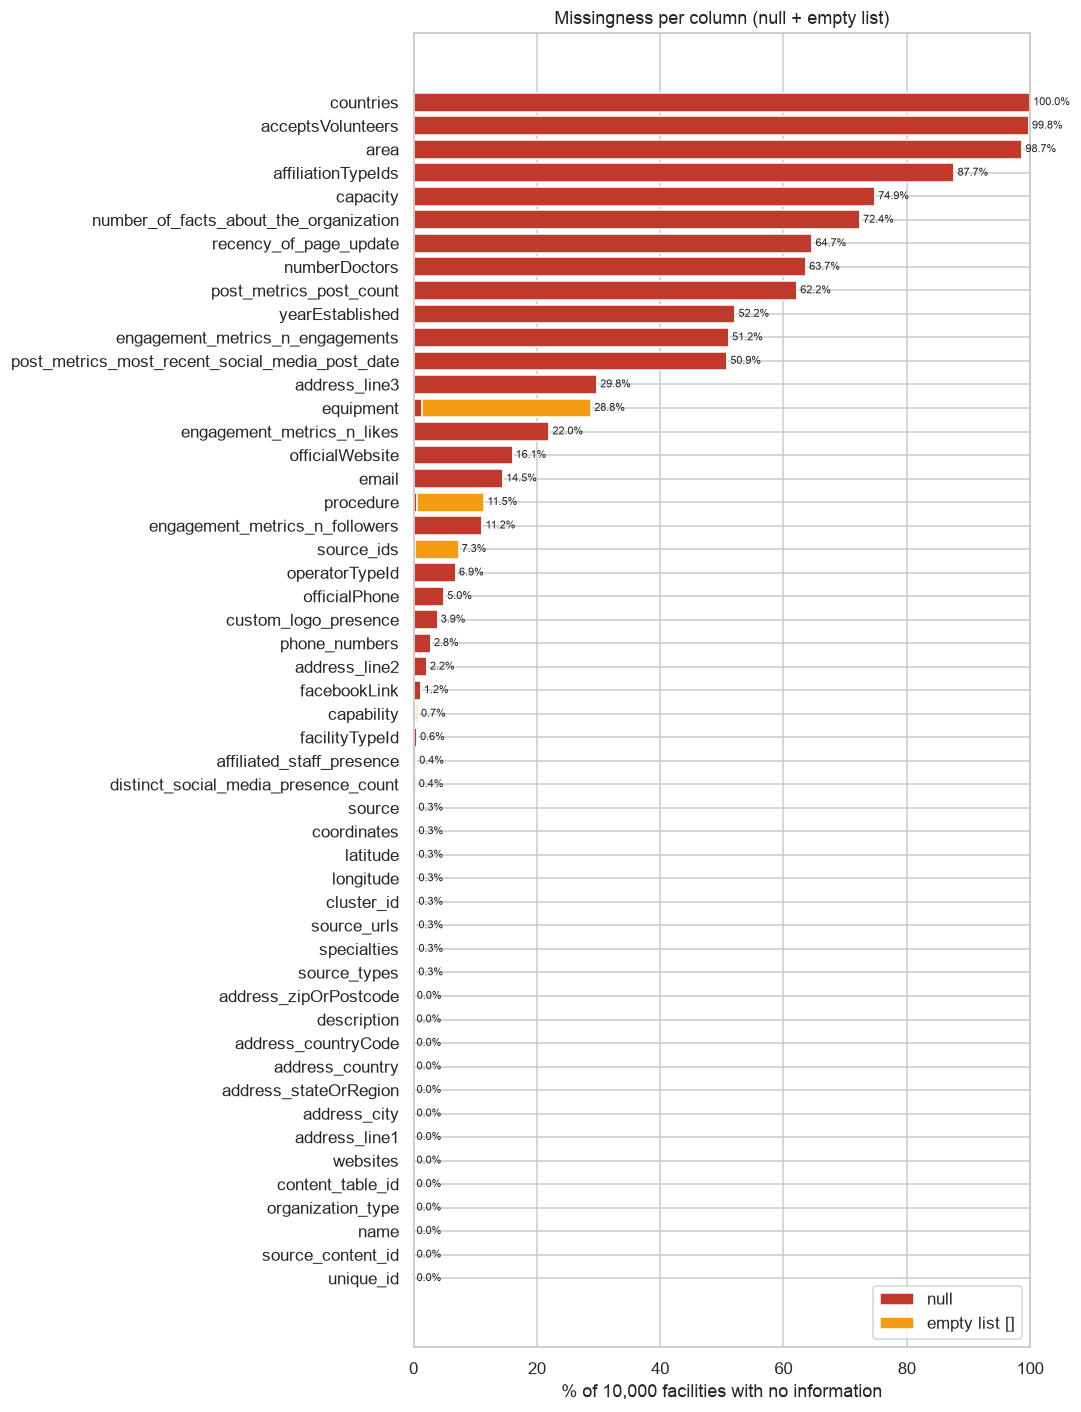

,pct_null,pct_empty_list,pct_no_info,group
countries,100.00,0.00,100.00,Location
acceptsVolunteers,99.79,0.00,99.79,Contact
area,98.75,0.00,98.75,Scale/history
affiliationTypeIds,87.64,0.10,87.74,Identity
capacity,74.87,0.00,74.87,Scale/history
number_of_facts_about_the_organization,72.42,0.00,72.42,Web/social signals
recency_of_page_update,64.70,0.00,64.70,Web/social signals
numberDoctors,63.68,0.00,63.68,Scale/history
post_metrics_post_count,62.22,0.00,62.22,Web/social signals
yearEstablished,52.20,0.00,52.20,Scale/history


In [8]:
# a list that is [] or contains only blank strings ([""]) carries no information
is_empty_list = pd.DataFrame({c: fac[c].map(lambda v: isinstance(v, list) and all(str(x).strip() == '' for x in v)) for c in LIST_COLS})
miss = pd.DataFrame({
    'pct_null': fac.isna().mean()*100,
    'pct_empty_list': is_empty_list.reindex(columns=fac.columns, fill_value=False).mean()*100,
})
miss['pct_no_info'] = miss.sum(axis=1)
miss['group'] = [col2group[c] for c in miss.index]
miss = miss.sort_values('pct_no_info', ascending=False)

fig, ax = plt.subplots(figsize=(10, 13))
ax.barh(miss.index, miss.pct_null, color='#c0392b', label='null')
ax.barh(miss.index, miss.pct_empty_list, left=miss.pct_null, color='#f39c12', label='empty list []')
ax.invert_yaxis(); ax.set_xlabel('% of 10,000 facilities with no information'); ax.legend(loc='lower right')
ax.set_title('Missingness per column (null + empty list)')
for i, v in enumerate(miss.pct_no_info): ax.text(v+0.5, i, f'{v:.1f}%', va='center', fontsize=7)
plt.tight_layout(); plt.show()
miss.round(2)

In [9]:
# Compare against the coverage stated in the challenge brief
stated = {'description':100,'capability':99.7,'procedure':92.5,'equipment':77.0,'yearEstablished':47.8,'numberDoctors':36.4,'capacity':25.2}
cmp = pd.DataFrame({'stated_coverage_%': stated,
                    'non_null_%': (100 - miss.loc[list(stated),'pct_null']).round(1),
                    'non_null_AND_non_empty_%': (100 - miss.loc[list(stated),'pct_no_info']).round(1)})
cmp

,stated_coverage_%,non_null_%,non_null_AND_non_empty_%
description,100.0,100.0,100.0
capability,99.7,99.6,99.3
procedure,92.5,99.4,88.5
equipment,77.0,98.6,71.2
yearEstablished,47.8,47.8,47.8
numberDoctors,36.4,36.3,36.3
capacity,25.2,25.1,25.1


The brief's coverage numbers match **"non‑null and non‑empty"** (e.g. equipment ≈77% once `[]` is counted as missing, even though only ~1.4% are literally null). Equipment is the weakest of the offering fields – yet equipment (MRI, dialysis machines, ventilators) is often the strongest *evidence* of a service.

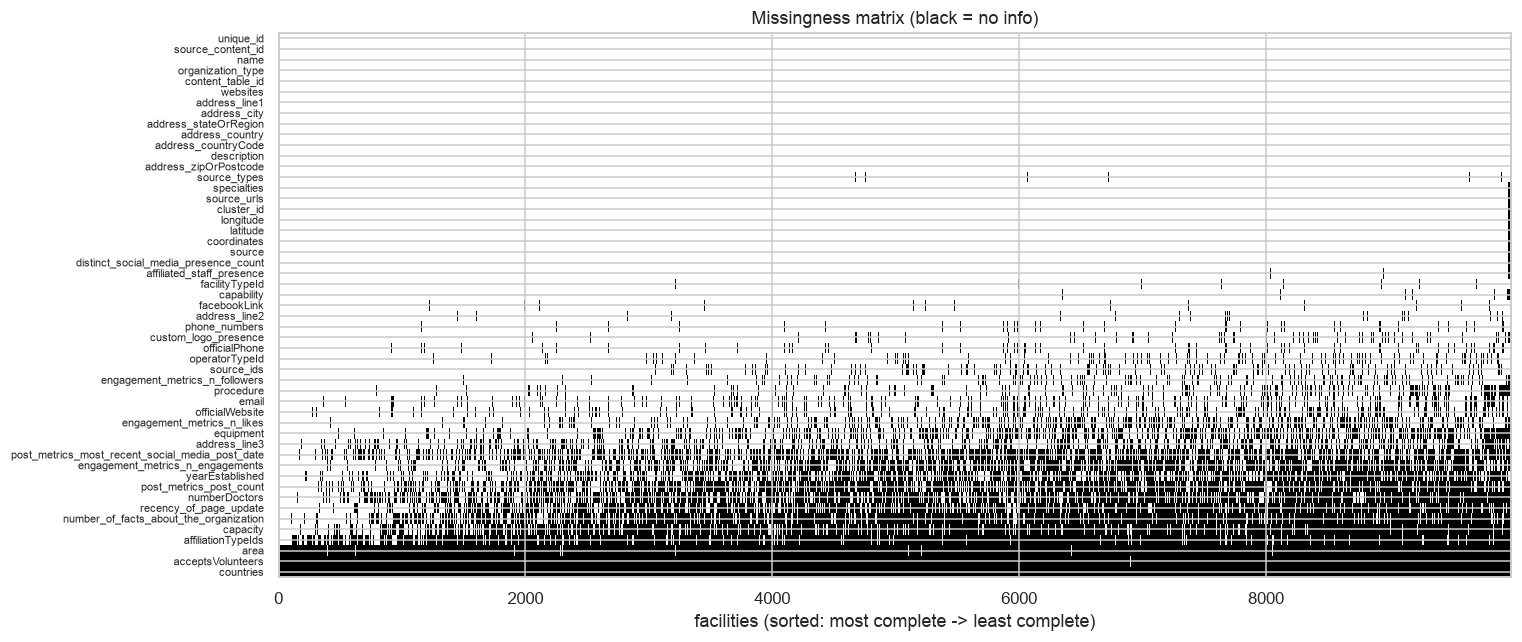

Missing fields per facility: {'count': 9989.0, 'mean': 10.5, 'std': 2.6, 'min': 1.0, '25%': 9.0, '50%': 11.0, '75%': 12.0, 'max': 30.0}


In [10]:
# Missingness matrix (rows sorted by completeness) – shows structure in what goes missing together
nofo = fac.isna() | is_empty_list.reindex(columns=fac.columns, fill_value=False)
order_cols = miss.index[::-1]
m = nofo[order_cols]
m = m.loc[m.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(m.T.values, aspect='auto', cmap='Greys', interpolation='nearest')
ax.set_yticks(range(len(order_cols))); ax.set_yticklabels(order_cols, fontsize=7)
ax.set_xlabel('facilities (sorted: most complete -> least complete)'); ax.set_title('Missingness matrix (black = no info)')
plt.tight_layout(); plt.show()

per_row = nofo.sum(axis=1)
print('Missing fields per facility:', per_row.describe().round(1).to_dict())

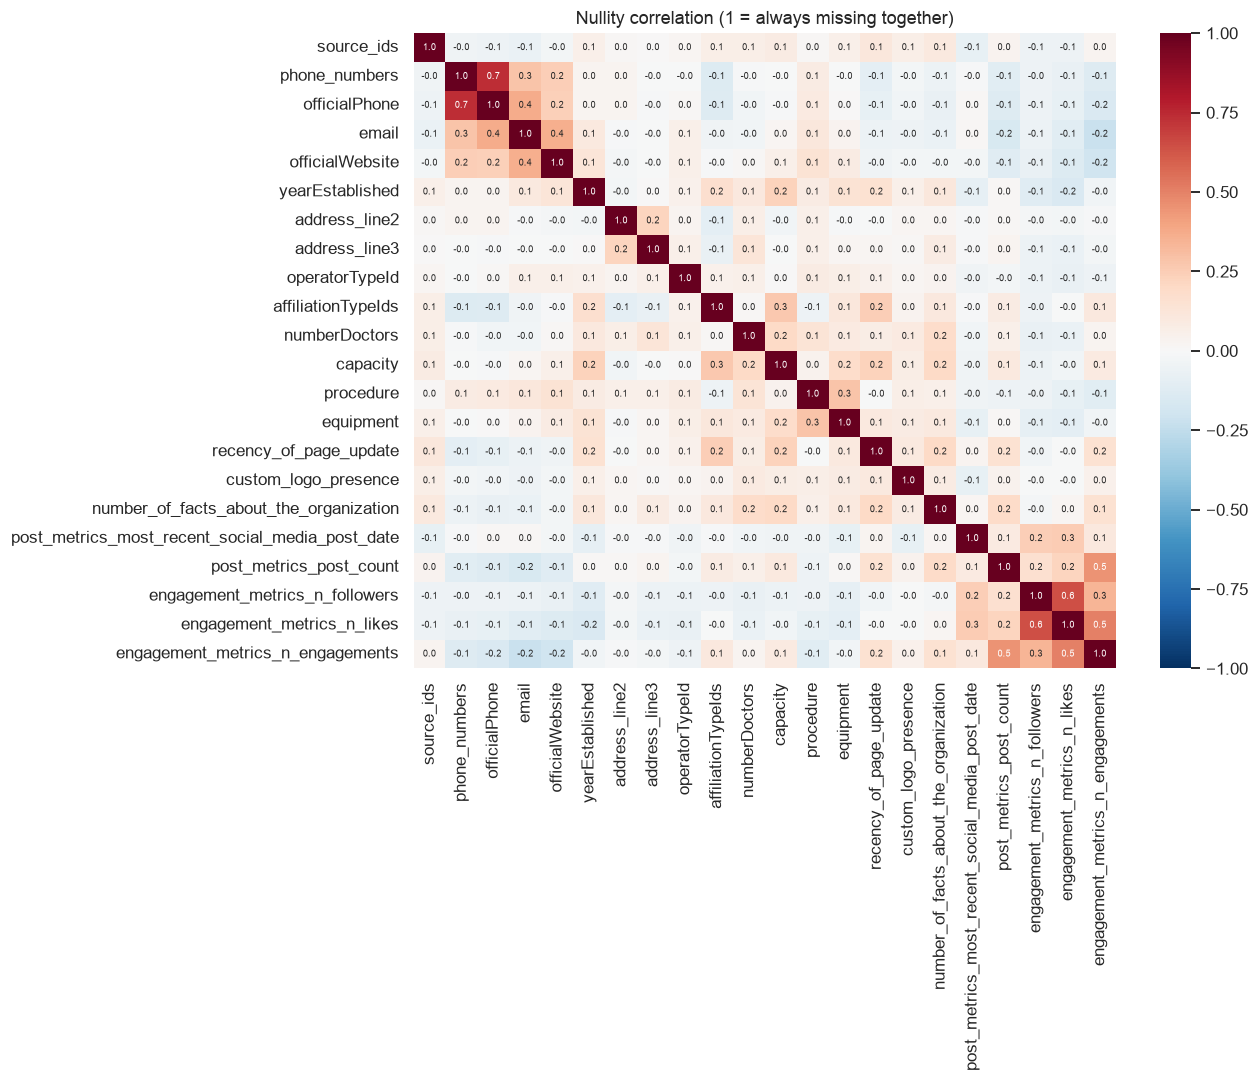

Strongest co-missing pairs:
phone_numbers                   officialPhone                       0.74
engagement_metrics_n_followers  engagement_metrics_n_likes          0.65
engagement_metrics_n_likes      engagement_metrics_n_engagements    0.51
post_metrics_post_count         engagement_metrics_n_engagements    0.45
officialPhone                   email                               0.37
email                           officialWebsite                     0.37
engagement_metrics_n_followers  engagement_metrics_n_engagements    0.34
procedure                       equipment                           0.29
phone_numbers                   email                               0.29
affiliationTypeIds              capacity                            0.27


In [11]:
# Nullity correlation: do fields go missing together? (only columns with 2–98% missing are informative)
cand = [c for c in fac.columns if 2 < miss.loc[c,'pct_no_info'] < 98]
nc = nofo[cand].astype(int).corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(nc, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot=True, fmt='.1f', annot_kws={'size':6})
ax.set_title('Nullity correlation (1 = always missing together)'); plt.tight_layout(); plt.show()

pairs = nc.where(np.triu(np.ones(nc.shape, bool), 1)).stack().sort_values(ascending=False)
print('Strongest co-missing pairs:'); print(pairs.head(10).round(2).to_string())

In [12]:
# Does missingness depend on facility type / operator?
key = ['yearEstablished','numberDoctors','capacity','equipment','procedure','email','officialWebsite','operatorTypeId']
by_type = nofo.groupby(fac['facilityTypeId'].fillna('<null>'))[key].mean().mul(100).round(1)
by_type.insert(0, 'n', fac['facilityTypeId'].fillna('<null>').value_counts())
print('% missing by facilityTypeId'); display(by_type.sort_values('n', ascending=False))
by_op = nofo.groupby(fac['operatorTypeId'].fillna('<null>'))[key].mean().mul(100).round(1)
by_op.insert(0, 'n', fac['operatorTypeId'].fillna('<null>').value_counts())
print('% missing by operatorTypeId'); display(by_op)

% missing by facilityTypeId


,n,yearEstablished,numberDoctors,capacity,equipment,procedure,email,officialWebsite,operatorTypeId
facilityTypeId,,,,,,,,,
hospital,5626,45.3,61.3,57.7,23.1,13.6,16.8,17.2,9.2
clinic,3782,60.5,66.4,96.7,36.1,8.6,11.7,14.3,3.4
dentist,490,65.5,64.3,99.2,34.5,8.8,9.4,15.5,1.2
<null>,57,47.4,98.2,100.0,42.1,15.8,14.0,12.3,54.4
doctor,21,81.0,81.0,100.0,61.9,14.3,14.3,14.3,4.8
farmacy,10,60.0,90.0,100.0,30.0,30.0,30.0,40.0,10.0
pharmacy,2,100.0,100.0,100.0,100.0,0.0,0.0,100.0,0.0
nursing_home,1,100.0,0.0,100.0,100.0,0.0,0.0,0.0,0.0


% missing by operatorTypeId


,n,yearEstablished,numberDoctors,capacity,equipment,procedure,email,officialWebsite,operatorTypeId
operatorTypeId,,,,,,,,,
<null>,687,62.2,73.5,75.3,40.2,21.0,22.4,24.5,100.0
government,2,50.0,100.0,50.0,0.0,50.0,50.0,50.0,0.0
private,8835,51.8,62.4,76.4,28.3,9.9,12.6,14.4,0.0
public,465,45.4,73.5,46.0,21.5,26.7,38.5,34.2,0.0


## 5. Constant / near-empty / redundant columns

In [13]:
rows = []
for c in fac.columns:
    s = fac[c].dropna()
    s_h = s.map(lambda v: json.dumps(v) if isinstance(v, list) else v)
    nu = s_h.nunique()
    top_share = s_h.value_counts(normalize=True).iloc[0]*100 if len(s) else np.nan
    rows.append((c, len(s), nu, round(top_share,1)))
cc = pd.DataFrame(rows, columns=['column','non_null','n_unique','top_value_share_%']).set_index('column')
flag = cc[(cc.n_unique <= 1) | (cc.non_null < 300) | (cc['top_value_share_%'] > 99)]
print('Constant, near-empty or ~single-valued columns -> little/no analytic value:')
display(flag)
print('source_content_id == content_table_id for', (fac.source_content_id == fac.content_table_id).mean()*100, '% of rows -> duplicate column')
print('address_countryCode values:', fac.address_countryCode.value_counts(dropna=False).to_dict())
print('countries non-null examples:', fac.countries.dropna().unique()[:5])

Constant, near-empty or ~single-valued columns -> little/no analytic value:


,non_null,n_unique,top_value_share_%
column,,,
organization_type,9989,1,100.0
acceptsVolunteers,21,2,66.7
address_country,9989,1,100.0
address_countryCode,9989,1,100.0
countries,0,0,NaN
area,125,93,4.8
source,9959,1,100.0


source_content_id == content_table_id for 100.0 % of rows -> duplicate column
address_countryCode values: {'IN': 9989}
countries non-null examples: <ArrowStringArray>
[]
Length: 0, dtype: str


## 6. Categorical fields

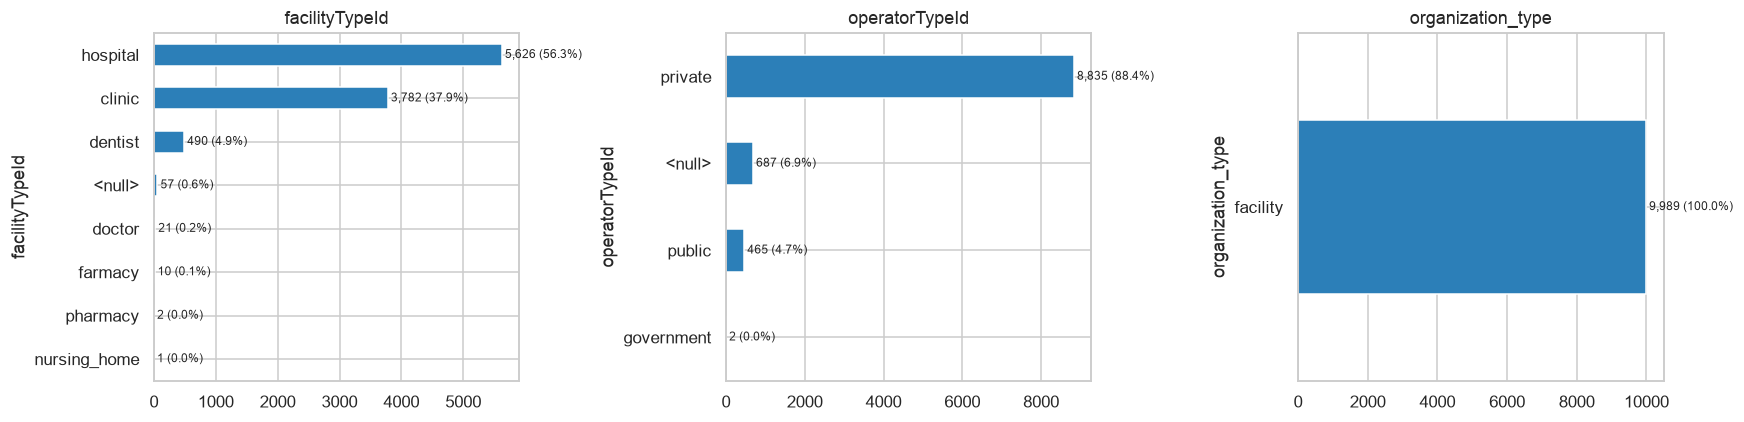

Note: 'farmacy' (typo) and 'pharmacy' are the same category; 'government' vs 'public' overlap.


operatorTypeId,<null>,government,private,public,All
facilityTypeId,,,,,
<null>,31,0,26,0,57
clinic,129,0,3627,26,3782
dentist,6,0,484,0,490
doctor,1,0,20,0,21
farmacy,1,0,8,1,10
hospital,519,2,4667,438,5626
nursing_home,0,0,1,0,1
pharmacy,0,0,2,0,2
All,687,2,8835,465,9989


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['facilityTypeId', 'operatorTypeId', 'organization_type']):
    vc = fac[c].fillna('<null>').value_counts()
    vc.plot.barh(ax=ax, color='#2c7fb8'); ax.invert_yaxis(); ax.set_title(c)
    for i, v in enumerate(vc): ax.text(v, i, f' {v:,} ({v/len(fac)*100:.1f}%)', va='center', fontsize=8)
plt.tight_layout(); plt.show()
print("Note: 'farmacy' (typo) and 'pharmacy' are the same category; 'government' vs 'public' overlap.")
ct = pd.crosstab(fac.facilityTypeId.fillna('<null>'), fac.operatorTypeId.fillna('<null>'), margins=True)
ct

In [15]:
# affiliationTypeIds and source_types are lists with heavy *repetition* (one entry per merged source)
def explode_counts(col, unique_per_row=True):
    s = fac[col].dropna()
    if unique_per_row: s = s.map(lambda l: sorted(set(map(str, l))))
    return s.explode().value_counts()

for col in ['affiliationTypeIds', 'source_types']:
    raw_c = explode_counts(col, unique_per_row=False); uniq_c = explode_counts(col, True)
    print(f'--- {col}: raw entries vs facilities having the value')
    display(pd.DataFrame({'raw_entries': raw_c, 'n_facilities': uniq_c}).fillna(0).astype(int))

st = fac.source_types.dropna().map(lambda l: '+'.join(sorted(set(l))))
print('Most common source-type combinations per facility:'); display(st.value_counts().head(10))

--- affiliationTypeIds: raw entries vs facilities having the value


,raw_entries,n_facilities
affiliationTypeIds,,
,4,4
DCI,1,1
INC,1,1
NAAC,1,1
NMC,1,1
RGUHS,1,1
academic,1818,470
clinical,1,1
community,130,112


--- source_types: raw entries vs facilities having the value


,raw_entries,n_facilities
source_types,,
overture,161777,9155
dynamic,82808,6932
constant,20621,3386
mongo_facility,5955,1124
mongo_ngo,1121,228


Most common source-type combinations per facility:


source_types
dynamic+overture                            3030
overture                                    2366
constant+dynamic+overture                   2192
dynamic                                      518
constant+dynamic+mongo_facility+overture     499
dynamic+mongo_facility+overture              390
constant+overture                            355
constant                                     119
constant+dynamic+mongo_ngo+overture           85
mongo_facility+overture                       83
Name: count, dtype: int64

In [16]:
for c in BOOL_COLS:
    print(c, fac[c].map({True:'true', False:'false'}).fillna('<null>').value_counts().to_dict())
print('\ndistinct_social_media_presence_count:'); print(fac.distinct_social_media_presence_count.value_counts(dropna=False).sort_index().to_dict())

acceptsVolunteers {'<null>': 9968, 'true': 14, 'false': 7}
affiliated_staff_presence {'true': 9250, 'false': 696, '<null>': 43}
custom_logo_presence {'true': 8600, 'false': 998, '<null>': 391}

distinct_social_media_presence_count:
{0.0: 434, 1.0: 1916, 2.0: 890, 3.0: 1673, 4.0: 1283, 5.0: 2736, 6.0: 714, 7.0: 107, 8.0: 50, 9.0: 148, 10.0: 1, 11.0: 2, nan: 35}


## 7. Nested list fields

`specialties`, `procedure`, `equipment`, `capability` are the **core evidence fields**. `specialties` uses a controlled camelCase vocabulary (mostly); the other three are free‑text sentences extracted by an LLM/IE pipeline.

List lengths. NOTE: every list is hard-capped at 50 items -> lists at 50 were TRUNCATED during extraction.


,median_len,mean_len,max_len,pct_at_cap_50,pct_empty,mean_dup_share_%
source_types,23.0,27.3,50.0,27.9,0.0,89.1
source_ids,17.0,22.7,50.0,22.0,7.0,78.1
phone_numbers,7.0,9.9,50.0,2.4,0.0,52.5
websites,12.0,18.7,50.0,13.6,0.0,12.8
affiliationTypeIds,2.0,4.8,50.0,0.2,0.1,33.0
specialties,24.0,28.0,50.0,28.8,0.0,55.1
procedure,11.0,16.8,50.0,11.3,7.2,3.7
equipment,3.0,6.1,50.0,1.9,21.8,4.3
capability,19.0,23.3,50.0,17.2,0.2,2.6
source_urls,10.0,17.0,50.0,12.4,0.0,3.8


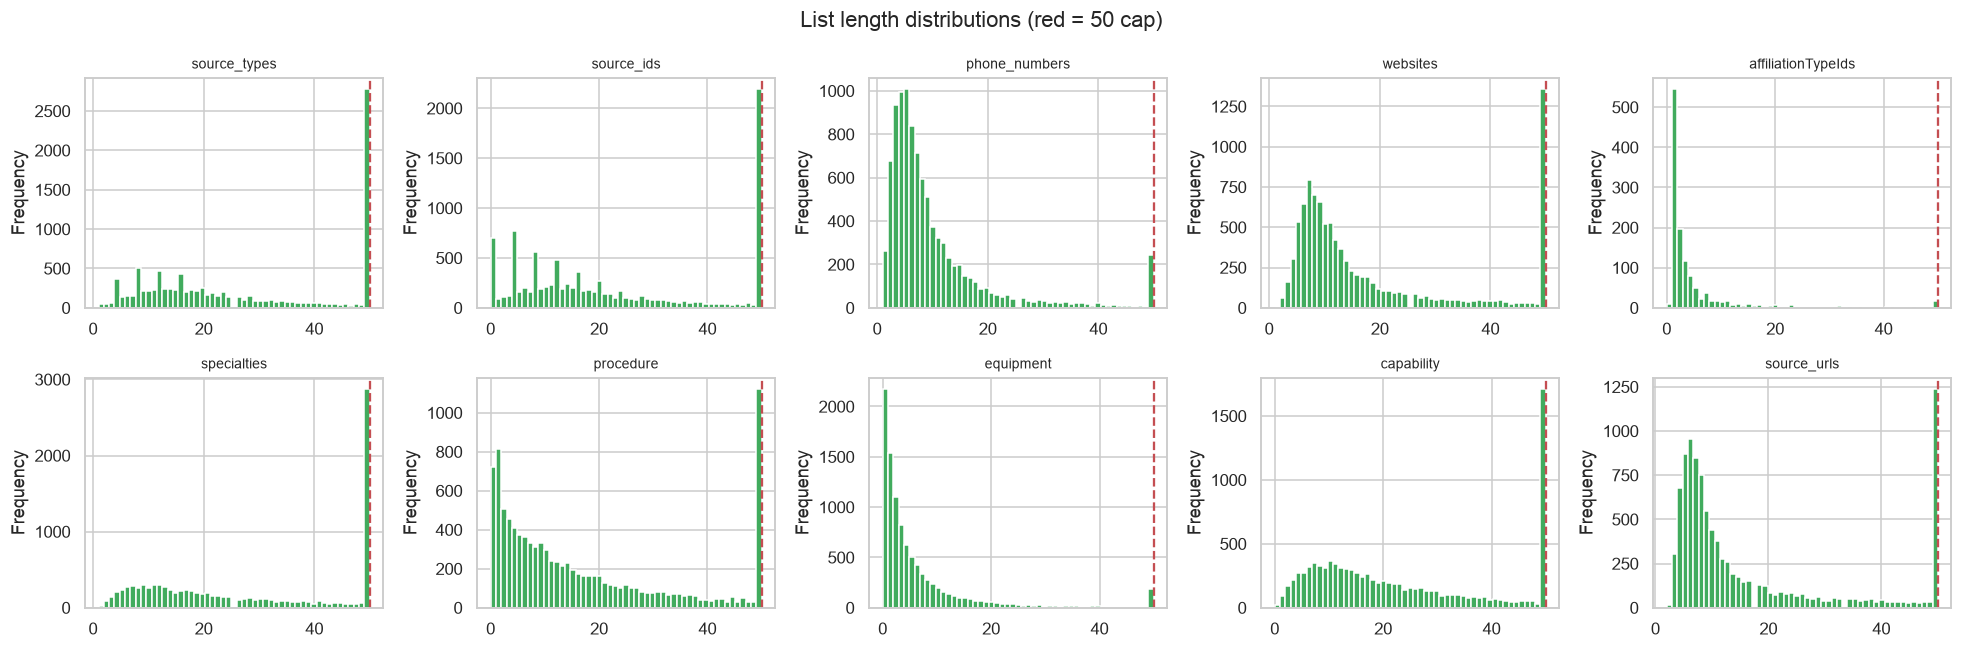

In [17]:
lens = pd.DataFrame({c: fac[c].map(lambda v: len(v) if isinstance(v, list) else np.nan) for c in LIST_COLS})
uniq_lens = pd.DataFrame({c: fac[c].map(lambda v: len(set(map(str, v))) if isinstance(v, list) else np.nan) for c in LIST_COLS})
summary = pd.DataFrame({
    'median_len': lens.median(), 'mean_len': lens.mean().round(1), 'max_len': lens.max(),
    'pct_at_cap_50': (lens == 50).mean().mul(100).round(1),
    'pct_empty': (lens == 0).mean().mul(100).round(1),
    'mean_dup_share_%': ((1 - uniq_lens/lens.replace(0, np.nan)).mean()*100).round(1),
})
print('List lengths. NOTE: every list is hard-capped at 50 items -> lists at 50 were TRUNCATED during extraction.')
display(summary)

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=False)
for ax, c in zip(axes.ravel(), LIST_COLS):
    lens[c].dropna().plot.hist(bins=51, ax=ax, color='#41ab5d'); ax.set_title(c, fontsize=9); ax.axvline(50, color='r', ls='--')
plt.suptitle('List length distributions (red = 50 cap)'); plt.tight_layout(); plt.show()

Distinct specialty strings: 2,933 | camelCase controlled-vocab-like: 2,072 | free-form: 861
Facilities covered by top-30 specialty codes: 77,907 mentions
Free-form specialty examples: ['painMedicinePMR', 'developmental–behavioralPediatrics', 'sportsMedicinePMR', 'upperGIAndForegutSurgery', 'addictionMedicinePM', 'neuromuscularMedicinePMR', 'TMJSurgery', 'Physiotherapy', 'Cardiology', 'Urology', 'Orthodontics', 'Orthopaedics', '', 'Neurosurgery', 'Nephrology']


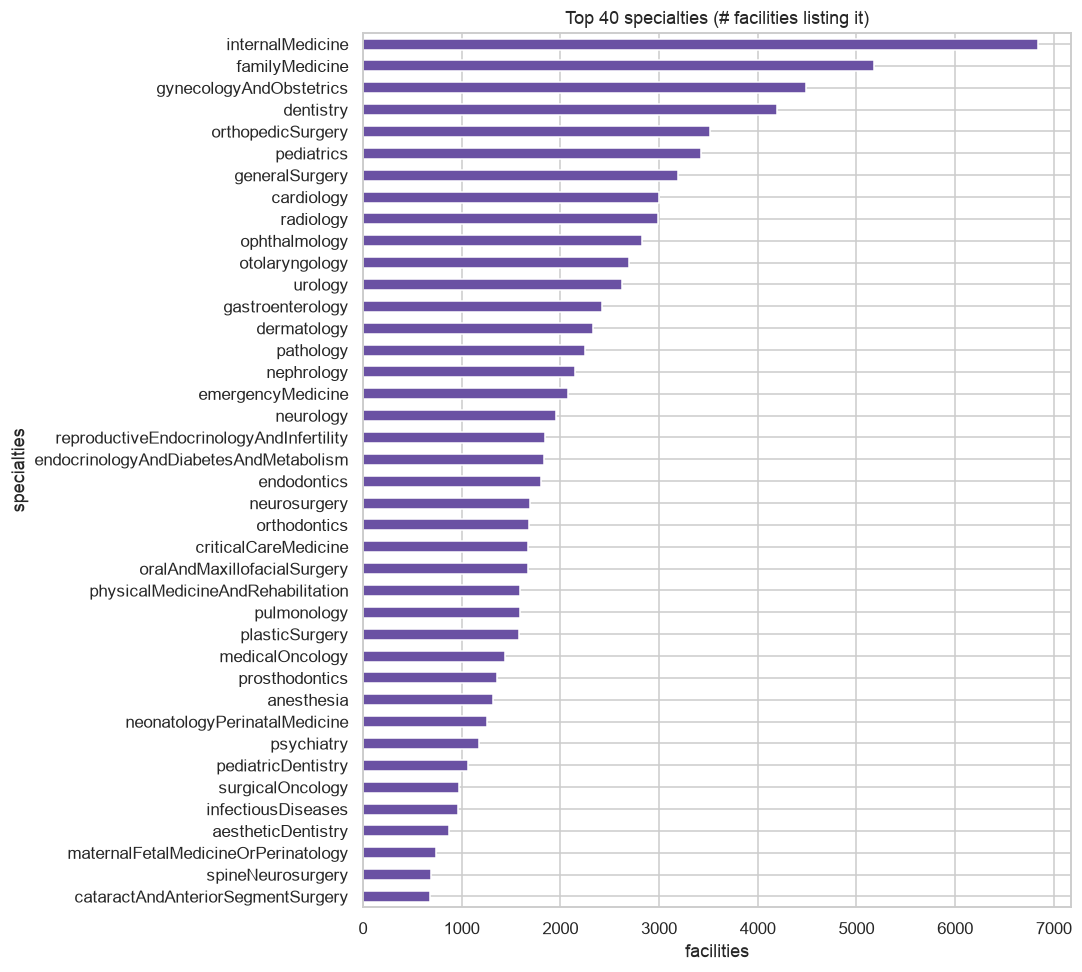

Long tail: specialties listed by only 1 facility: 1976


In [18]:
# Specialties vocabulary
sp_rows = fac.specialties.dropna().map(lambda l: set(l))
sp_fac = sp_rows.explode().value_counts()
camel = sp_fac.index.to_series().str.fullmatch(r'[a-z]+(?:[A-Z][a-z]+)*')
print(f'Distinct specialty strings: {len(sp_fac):,} | camelCase controlled-vocab-like: {camel.sum():,} | free-form: {(~camel).sum():,}')
print(f'Facilities covered by top-30 specialty codes: {sp_fac.head(30).sum():,} mentions')
print('Free-form specialty examples:', sp_fac[~camel.values].head(15).index.tolist())

fig, ax = plt.subplots(figsize=(10, 9))
sp_fac.head(40).plot.barh(ax=ax, color='#6a51a3'); ax.invert_yaxis()
ax.set_title('Top 40 specialties (# facilities listing it)'); ax.set_xlabel('facilities'); plt.tight_layout(); plt.show()
print('Long tail: specialties listed by only 1 facility:', (sp_fac == 1).sum())

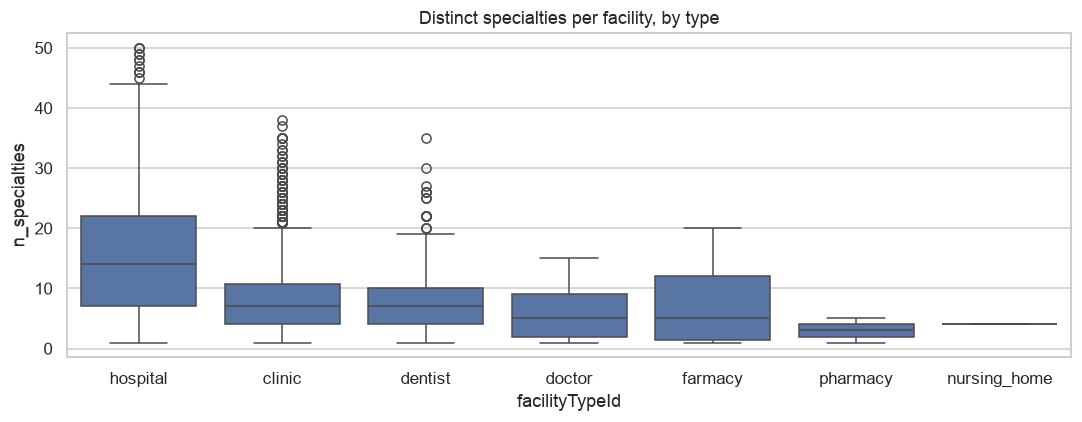

internalMedicine listed by 68% of facilities -> near-default, low information


In [19]:
# Specialty counts per facility vs type -> a 'clinic' listing 40+ specialties is a red flag (merged / boilerplate)
nsp = sp_rows.map(len).rename('n_specialties')
tmp = pd.concat([nsp, fac.facilityTypeId], axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=tmp, x='facilityTypeId', y='n_specialties', ax=ax, order=fac.facilityTypeId.value_counts().index)
ax.set_title('Distinct specialties per facility, by type'); plt.tight_layout(); plt.show()
print('internalMedicine listed by', f"{sp_fac.get('internalMedicine',0)/len(fac)*100:.0f}% of facilities -> near-default, low information")

In [20]:
# Free-text evidence items: equipment / procedure / capability
def top_items(col, n=25):
    s = fac[col].dropna().map(lambda l: {str(x).strip().lower() for x in l} - {''}).explode().dropna()
    return s.value_counts().head(n)
for col in ['equipment', 'procedure', 'capability']:
    items = fac[col].dropna().explode().dropna().astype(str)
    print(f'=== {col}: {len(items):,} items, {items.str.lower().nunique():,} distinct, median item length {items.str.len().median():.0f} chars')
    display(top_items(col, 20).to_frame('n_facilities'))

=== equipment: 60,070 items, 33,887 distinct, median item length 29 chars


,n_facilities
equipment,
ct scanner,524
wheelchair accessible entrance and exit,359
mri scanner,322
wheelchair-accessible entrance and exit,310
x-ray imaging equipment,280
wheel chair accessible entrance and exit,267
ultrasound machine,212
ecg machine,208
digital x-ray system,192


=== procedure: 167,272 items, 82,717 distinct, median item length 27 chars


,n_facilities
procedure,
dental implants,569
root canal treatment,482
teeth whitening,401
laparoscopic surgery,338
cataract surgery,288
laser dentistry,283
root canal treatment (rct),265
provides dental implants,240
arthroscopy,232


=== capability: 232,295 items, 165,169 distinct, median item length 41 chars


,n_facilities
capability,
outpatient dental clinic,531
operates 24/7,492
24/7 emergency care,486
provides 24/7 emergency care,472
nabh accredited,461
private hospital,450
inpatient and outpatient services,442
open 24/7,377
multispeciality hospital,345


In [21]:
# Extraction artefacts inside evidence lists: blank items and LLM 'nothing found' placeholder sentences
PLACEHOLDER = r'^(no|not|none)\b.*\b(provided|mentioned|listed|available|specified|found|given|stated)\b|not (provided|mentioned|specified) in'
art = {}
for col in ['specialties','procedure','equipment','capability']:
    items = fac[col].dropna().explode().dropna().astype(str)
    blank = items.str.strip() == ''
    ph = items.str.lower().str.contains(PLACEHOLDER, regex=True)
    art[col] = {'facilities_with_blank_item': int(fac[col].map(lambda l: isinstance(l, list) and any(str(x).strip()=='' for x in l)).sum()),
                'blank_items': int(blank.sum()), 'placeholder_items': int(ph.sum()),
                'facilities_with_placeholder': int(items[ph].index.nunique())}
display(pd.DataFrame(art).T)
ex = fac.equipment.dropna().explode().dropna().astype(str)
print('Placeholder examples (these must NOT count as evidence):')
for x in ex[ex.str.lower().str.contains(PLACEHOLDER)].drop_duplicates().head(6): print('  -', x)

,facilities_with_blank_item,blank_items,placeholder_items,facilities_with_placeholder
specialties,9,9,0,0
procedure,2310,3625,272,255
equipment,2312,4072,363,321
capability,713,830,30,25


Placeholder examples (these must NOT count as evidence):
  - No equipment details provided for FMRI in the provided content.
  - No specific medical imaging devices or equipment listed for Fortis Hospital Anandpur, Kolkata in provided content.
  - No specific medical equipment listed for Civil Hospital in the provided content.
  - No specific medical equipment listed for Fortis Hospital, Mohali in the provided content
  - No specific medical equipment or devices listed for Amrita Institute of Medical Sciences in the provided content.
  - No equipment details provided for MGM Healthcare in the provided content.


In [22]:
print('Example evidence for a random facility:')
r = fac.dropna(subset=['equipment']).sample(1, random_state=7).iloc[0]
print('NAME:', r['name'], '|', r['address_city'], r['address_stateOrRegion'], '| type:', r['facilityTypeId'])
for c in ['specialties','procedure','equipment','capability']:
    print(f'\n{c.upper()} ({len(r[c])}):')
    for x in r[c][:8]: print('  -', x)

Example evidence for a random facility:
NAME: Sreerudra Ayurveda Multispeciality Hospital | Alappuzha Kerala | type: hospital

SPECIALTIES (50):
  - gynecologyAndObstetrics
  - endocrinologyAndDiabetesAndMetabolism
  - gastroenterology
  - nephrology
  - rheumatology
  - dermatology
  - medicalOncology
  - neurology

PROCEDURE (50):
  - Offers Panchakarma and rejuvenation therapies
  - Provides treatment for spinal problems
  - Provides treatment for kidney disorders
  - Provides treatment for rectal problems
  - Provides treatment for varicose veins
  - Provides treatment for liver disorders
  - Provides treatment for arthritis
  - Provides treatment for skin complaints

EQUIPMENT (2):
  - Slit proctoscope used for Kshara Sutra application
  - Infrared heating device used for Agni Karma cauterization

CAPABILITY (40):
  - Ayurveda multispeciality hospital in Alappuzha, Kerala, India
  - NABH accredited facility
  - Spine treatment center offering complete Ayurvedic care
  - Offers Pan

## 8. Location

### 8a. States

In [23]:
pin = pd.read_csv(f'{DATA}/india_post_pincode_directory.csv', dtype=str, low_memory=False)
pin['pincode'] = pin['pincode'].str.strip()
pin['lat'] = pd.to_numeric(pin['latitude'], errors='coerce'); pin['lon'] = pd.to_numeric(pin['longitude'], errors='coerce')
pin_ok = pin[in_india(pin.lat, pin.lon)]
CANON = sorted(pin.statename.dropna().unique())
print('Canonical state names (from India Post):', CANON)

s_raw = fac.address_stateOrRegion
print(f'\nDistinct raw state strings in facilities: {s_raw.nunique()}  (India has 28 states + 8 UTs = 36)')

Canonical state names (from India Post): ['ANDAMAN AND NICOBAR ISLANDS', 'ANDHRA PRADESH', 'ARUNACHAL PRADESH', 'ASSAM', 'BIHAR', 'CHANDIGARH', 'CHHATTISGARH', 'DELHI', 'GOA', 'GUJARAT', 'HARYANA', 'HIMACHAL PRADESH', 'JAMMU AND KASHMIR', 'JHARKHAND', 'KARNATAKA', 'KERALA', 'LADAKH', 'LAKSHADWEEP', 'MADHYA PRADESH', 'MAHARASHTRA', 'MANIPUR', 'MEGHALAYA', 'MIZORAM', 'NAGALAND', 'ODISHA', 'PUDUCHERRY', 'PUNJAB', 'RAJASTHAN', 'SIKKIM', 'TAMIL NADU', 'TELANGANA', 'THE DADRA AND NAGAR HAVELI AND DAMAN AND DIU', 'TRIPURA', 'UTTAR PRADESH', 'UTTARAKHAND', 'WEST BENGAL']

Distinct raw state strings in facilities: 234  (India has 28 states + 8 UTs = 36)


In [24]:
ALIAS = {'TAMILNADU':'TAMIL NADU','ORISSA':'ODISHA','UP':'UTTAR PRADESH','U P':'UTTAR PRADESH','CHATTISGARH':'CHHATTISGARH',
         'NCT OF DELHI':'DELHI','NEW DELHI':'DELHI','PONDICHERRY':'PUDUCHERRY','PUNJAB REGION':'PUNJAB','TS':'TELANGANA',
         'J AND K':'JAMMU AND KASHMIR','J K':'JAMMU AND KASHMIR','UTTARANCHAL':'UTTARAKHAND','MAHARASTRA':'MAHARASHTRA',
         'TELENGANA':'TELANGANA','KARNATKA':'KARNATAKA','PUDDUCHERRY':'PUDUCHERRY'}
canon_set = set(CANON)
def norm_state(s):
    if pd.isna(s): return np.nan
    t = re.sub(r'[^A-Z ]', ' ', s.upper().replace('&', ' AND ')); t = re.sub(r'\s+', ' ', t).strip()
    if t in canon_set: return t
    if t in ALIAS: return ALIAS[t]
    for c in sorted(canon_set, key=len, reverse=True):       # e.g. "GHAZIABAD, UTTAR PRADESH"
        if re.search(rf'\b{c}\b', t): return c
    return np.nan

fac['state_norm'] = fac.address_stateOrRegion.map(norm_state)
unmapped = fac.loc[fac.state_norm.isna(), 'address_stateOrRegion'].value_counts()
print(f'Rows whose state string is not a state at all (city/district names in the state field): {unmapped.sum()} '
      f'across {len(unmapped)} distinct values'); print(unmapped.head(30).to_dict())

Rows whose state string is not a state at all (city/district names in the state field): 284 across 159 distinct values
{'Thane': 13, 'Mumbai': 12, 'Navi Mumbai': 12, 'Pune': 10, 'Chennai': 10, 'Hyderabad': 9, 'Thiruvananthapuram': 7, 'Kollam': 5, 'Malappuram': 5, 'Dhule': 4, 'Indore': 4, 'Erode': 4, 'Kushinagar': 4, 'Ernakulam': 4, 'Ghaziabad': 4, 'Ahmedabad': 3, 'Idukki': 3, 'Mohali': 3, 'Palghar': 3, 'Sangli': 3, 'Namakkal': 2, 'Latur': 2, 'Thanjavur': 2, 'Guntur': 2, 'Kupwara': 2, 'North 24 Parganas': 2, 'Dakshin Kannad': 2, 'Prakasam': 2, 'Jalandhar': 2, 'Palakkad': 2}


### 8b. PIN codes – format, validity, and PIN-derived state/district

In [25]:
z = fac.address_zipOrPostcode.astype('string')
z_clean = z.str.replace(r'\s+', '', regex=True)
fmt = pd.Series(np.select([z.isna().to_numpy(bool), z.str.fullmatch(r'\d{6}').fillna(False).to_numpy(bool), z_clean.str.fullmatch(r'\d{6}').fillna(False).to_numpy(bool)],
                          ['missing', '6 digits', '6 digits w/ space'], 'malformed'), index=fac.index)
print(fmt.value_counts().to_dict())
print('Malformed examples:', z[fmt == 'malformed'].head(15).tolist())
fac['pin6'] = z_clean.where(z_clean.str.fullmatch(r'\d{6}').fillna(False)).astype(object)

# Lookup tables from India Post
pin_state = pin.dropna(subset=['statename']).groupby('pincode')['statename'].agg(lambda s: s.mode().iloc[0])
pin_district = pin.dropna(subset=['district']).groupby('pincode')['district'].agg(lambda s: s.mode().iloc[0])
pin_nstates = pin.dropna(subset=['statename']).groupby('pincode')['statename'].nunique()
pin_cent = pin_ok.groupby('pincode')[['lat','lon']].median()

fac['pin_in_directory'] = fac.pin6.isin(pin_state.index)
fac['pin_state'] = fac.pin6.map(pin_state); fac['pin_district'] = fac.pin6.map(pin_district)
print(f"\nValid-format PINs found in India Post directory: {fac.pin_in_directory.sum():,} / {fac.pin6.notna().sum():,} "
      f"({fac.pin_in_directory.sum()/fac.pin6.notna().sum()*100:.1f}%)")
print('PIN first digit = postal zone:'); print(fac.pin6.str[0].value_counts().sort_index().to_dict())

{'6 digits': 9762, '6 digits w/ space': 153, 'malformed': 70, 'missing': 4}
Malformed examples: ['10', '75', '58', '5600', '641-602', '85', '23', '56', '62', '124...', '20201', '2110...', '560-105', '40', '66']



Valid-format PINs found in India Post directory: 9,700 / 9,915 (97.8%)
PIN first digit = postal zone:
{'0': 6, '1': 1448, '2': 1083, '3': 1404, '4': 2125, '5': 1296, '6': 1355, '7': 780, '8': 417, '9': 1}


In [26]:
# Fill state from PIN where the state field held a city name, then check agreement of address state vs PIN state
fac['state_final'] = fac.state_norm.fillna(fac.pin_state)
both = fac.state_norm.notna() & fac.pin_state.notna()
fac['state_pin_conflict'] = both & (fac.state_norm != fac.pin_state)
print(f'State recovered from PIN for {(fac.state_norm.isna() & fac.pin_state.notna()).sum()} rows; still unknown: {fac.state_final.isna().sum()}')
print(f'Address-state vs PIN-state CONFLICT: {fac.state_pin_conflict.sum()} of {both.sum()} ({fac.state_pin_conflict.sum()/both.sum()*100:.1f}%)')
display(fac.loc[fac.state_pin_conflict, ['name','address_city','address_stateOrRegion','pin6','pin_state','pin_district']].head(12))
pd.crosstab(fac.loc[fac.state_pin_conflict,'state_norm'], fac.loc[fac.state_pin_conflict,'pin_state']).stack().sort_values(ascending=False).head(10)

State recovered from PIN for 272 rows; still unknown: 12
Address-state vs PIN-state CONFLICT: 65 of 9428 (0.7%)


,name,address_city,address_stateOrRegion,pin6,pin_state,pin_district
0,Aravind Eye Hospital,Hyderabad,Telangana,110002,DELHI,CENTRAL
42,Srinivasa Nursing Home,Adilabad,Andhra Pradesh,504001,TELANGANA,ADILABAD
64,"Krishna Institute of Medical Sciences, Hyderabad",Hyderabad,Andhra Pradesh,500003,TELANGANA,HYDERABAD
164,District Hospital Durg,Durg,Chhattisgarh,262701,UTTAR PRADESH,KHERI
188,Omega Hospital,Hyderabad,Telengana,530040,ANDHRA PRADESH,VISAKHAPATANAM
210,Medicover Hospitals,Hyderabad,Telangana,431003,MAHARASHTRA,AURANGABAD
277,Aditya Hospitals,Guntur,Andhra Pradesh,504215,TELANGANA,MANCHERIAL
282,Care Hospitals,Hyderabad,Telangana,530002,ANDHRA PRADESH,VISAKHAPATANAM
331,Gayatri Hospital,Ghaziabad,Up,425001,MAHARASHTRA,JALGAON
435,Asha Hospital,Hyderabad,Andhra Pradesh,500029,TELANGANA,HYDERABAD


state_norm      pin_state     
ANDHRA PRADESH  TELANGANA         25
TRIPURA         TELANGANA          6
DELHI           UTTAR PRADESH      4
UTTAR PRADESH   DELHI              2
DELHI           HARYANA            2
CHANDIGARH      PUNJAB             2
TELANGANA       ANDHRA PRADESH     2
HARYANA         DELHI              1
PUNJAB          HARYANA            1
TELANGANA       MAHARASHTRA        1
dtype: int64

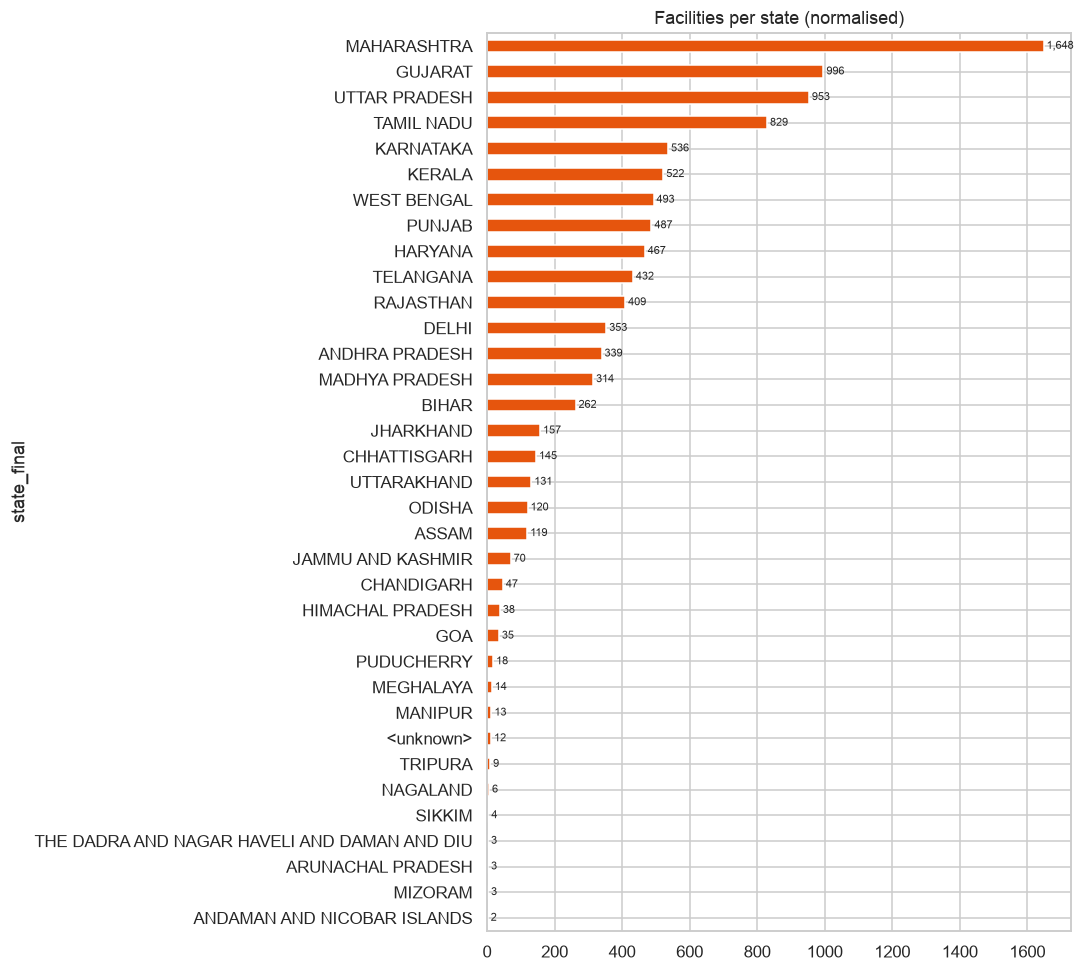

States/UTs with ZERO facilities: ['LADAKH', 'LAKSHADWEEP']
Top 5 states hold 50% of all facilities -> strong coverage bias (urban / western & southern India)


In [27]:
sc = fac.state_final.fillna('<unknown>').value_counts()
fig, ax = plt.subplots(figsize=(10, 9))
sc.plot.barh(ax=ax, color='#e6550d'); ax.invert_yaxis(); ax.set_title('Facilities per state (normalised)')
for i, v in enumerate(sc): ax.text(v, i, f' {v:,}', va='center', fontsize=7)
plt.tight_layout(); plt.show()
missing_states = sorted(set(CANON) - set(sc.index))
print('States/UTs with ZERO facilities:', missing_states)
print(f'Top 5 states hold {sc.head(5).sum()/len(fac)*100:.0f}% of all facilities -> strong coverage bias (urban / western & southern India)')

### 8c. Cities

In [28]:
city = fac.address_city.str.strip()
print(f'Distinct city strings: {city.nunique():,} | case-folded: {city.str.lower().nunique():,}')
display(city.value_counts().head(30).to_frame('facilities').T)
# Known spelling variants of the same city
variants = {'Bengaluru/Bangalore': ['bangalore','bengaluru'], 'Gurugram/Gurgaon': ['gurgaon','gurugram'],
            'Mumbai/Bombay': ['mumbai','bombay','navi mumbai'], 'Kolkata/Calcutta':['kolkata','calcutta'],
            'Chennai/Madras':['chennai','madras'], 'Vadodara/Baroda':['vadodara','baroda'], 'Thiruvananthapuram/Trivandrum':['thiruvananthapuram','trivandrum'],
            'Mysuru/Mysore':['mysore','mysuru'], 'Puducherry/Pondicherry':['puducherry','pondicherry']}
cl = city.str.lower()
print({k: {v:int((cl==v).sum()) for v in vs} for k, vs in variants.items()})
print('Cities that equal the state name / look like localities:', (cl == fac.address_stateOrRegion.str.lower()).sum())

Distinct city strings: 1,628 | case-folded: 1,628


address_city,Mumbai,Hyderabad,Chennai,Ahmedabad,Pune,Kolkata,Bangalore,Jaipur,Surat,Lucknow,New Delhi,Patna,Nagpur,Delhi,Vadodara,Bengaluru,Nashik,Ludhiana,Indore,Thane,Bhopal,Gurgaon,Amritsar,Raipur,Coimbatore,Ghaziabad,Jalandhar,Noida,Varanasi,Ranchi
facilities,364,358,326,325,274,243,204,190,164,155,146,138,136,133,128,109,104,97,95,85,84,82,77,77,75,72,72,69,68,66


{'Bengaluru/Bangalore': {'bangalore': 204, 'bengaluru': 109}, 'Gurugram/Gurgaon': {'gurgaon': 82, 'gurugram': 65}, 'Mumbai/Bombay': {'mumbai': 364, 'bombay': 0, 'navi mumbai': 58}, 'Kolkata/Calcutta': {'kolkata': 243, 'calcutta': 0}, 'Chennai/Madras': {'chennai': 326, 'madras': 0}, 'Vadodara/Baroda': {'vadodara': 128, 'baroda': 4}, 'Thiruvananthapuram/Trivandrum': {'thiruvananthapuram': 52, 'trivandrum': 20}, 'Mysuru/Mysore': {'mysore': 10, 'mysuru': 11}, 'Puducherry/Pondicherry': {'puducherry': 5, 'pondicherry': 9}}
Cities that equal the state name / look like localities: 218


### 8d. Coordinates

In [29]:
lat, lon = fac.latitude, fac.longitude
inside = in_india(lat, lon)
print(f'Have coordinates: {lat.notna().sum():,} | inside India bbox: {inside.sum():,} | OUTSIDE India: {(lat.notna() & ~inside).sum()}')
swapped = lat.notna() & ~inside & in_india(lon, lat)
print('Look lat/lon swapped:', swapped.sum(), '| exactly (0,0):', ((lat==0)&(lon==0)).sum())
display(fac.loc[lat.notna() & ~inside, ['name','address_city','address_stateOrRegion','latitude','longitude']].head(15))

# Distance from facility coordinates to its PIN centroid
fac = fac.join(pin_cent.rename(columns={'lat':'pin_lat','lon':'pin_lon'}), on='pin6')
fac['km_to_pin'] = haversine_km(fac.latitude, fac.longitude, fac.pin_lat, fac.pin_lon)
d = fac.km_to_pin.dropna()
print('\nDistance facility-coords -> PIN centroid (km):', d.describe(percentiles=[.5,.75,.9,.95,.99]).round(1).to_dict())
for t in [10, 25, 50, 100, 500]:
    print(f'  > {t:>3} km: {(d>t).sum():>5} ({(d>t).mean()*100:.1f}%)')

Have coordinates: 9,959 | inside India bbox: 9,953 | OUTSIDE India: 6
Look lat/lon swapped: 0 | exactly (0,0): 0


,name,address_city,address_stateOrRegion,latitude,longitude
1614,Cura Imaging & Gastro Clinic,Nagpur,Maharashtra,2.952934,41.387157
3841,Hzb Arogyam Multispeciality Hospital,Hazaribagh,Jharkhand,46.073227,106.171875
7184,The Family Tree Hospital,Tirupati,Andhra Pradesh,32.962585,7.479839
8263,Sanjivani Multi Speciality Hospital,Chengannur,Alappuzha,59.949684,-38.262634
8910,Krishna Hospital Multispeciality,Lucknow,Uttar Pradesh,-81.706299,26.953110
9717,Cardia Health Care,Noida,Uttar Pradesh,7.710991,109.687500



Distance facility-coords -> PIN centroid (km): {'count': 9673.0, 'mean': 49.3, 'std': 225.7, 'min': 0.0, '50%': 2.4, '75%': 13.1, '90%': 153.6, '95%': 293.6, '99%': 597.9, 'max': 12437.2}
  >  10 km:  2617 (27.1%)
  >  25 km:  1965 (20.3%)
  >  50 km:  1562 (16.1%)
  > 100 km:  1227 (12.7%)
  > 500 km:   195 (2.0%)


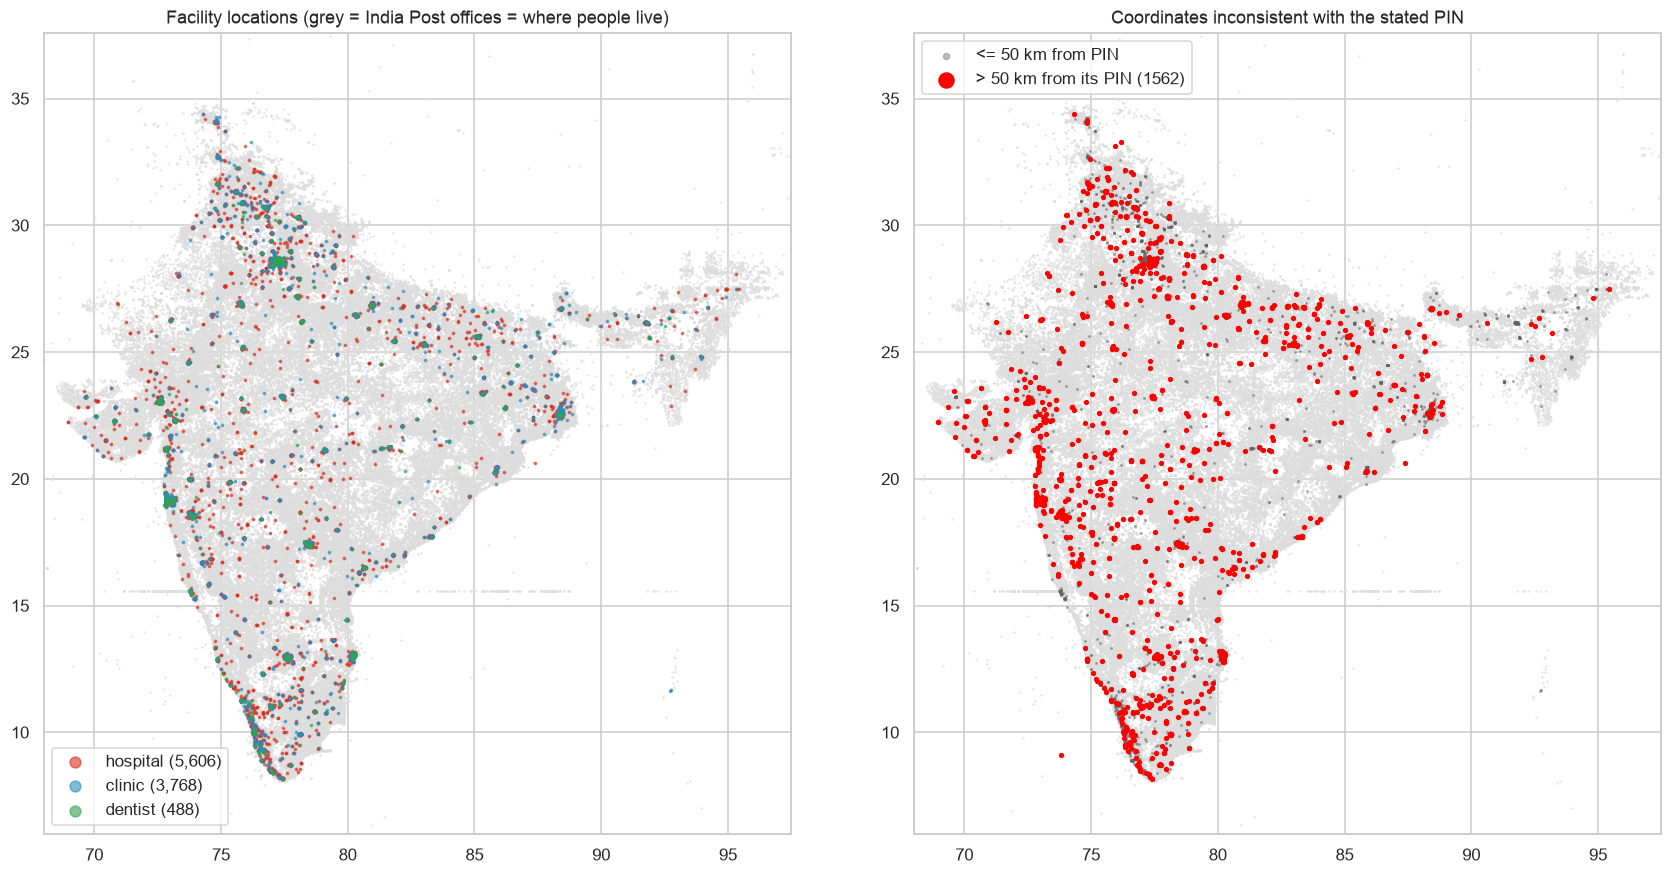

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
ax = axes[0]
ax.scatter(pin_ok.lon, pin_ok.lat, s=0.2, c='#dddddd', rasterized=True)   # India Post offices as a basemap silhouette
for t, col in zip(['hospital','clinic','dentist'], ['#d7301f','#2b8cbe','#31a354']):
    m = (fac.facilityTypeId == t) & inside
    ax.scatter(fac.loc[m,'longitude'], fac.loc[m,'latitude'], s=2, c=col, label=f'{t} ({m.sum():,})', alpha=.6)
ax.set_xlim(*INDIA_BBOX['lon']); ax.set_ylim(*INDIA_BBOX['lat']); ax.set_aspect('equal'); ax.legend(markerscale=5)
ax.set_title('Facility locations (grey = India Post offices = where people live)')
ax = axes[1]
ax.scatter(pin_ok.lon, pin_ok.lat, s=0.2, c='#dddddd', rasterized=True)
far = fac.km_to_pin > 50
ax.scatter(fac.loc[~far & inside,'longitude'], fac.loc[~far & inside,'latitude'], s=1, c='#636363', alpha=.4, label='<= 50 km from PIN')
ax.scatter(fac.loc[far & inside,'longitude'], fac.loc[far & inside,'latitude'], s=6, c='red', label=f'> 50 km from its PIN ({far.sum()})')
ax.set_xlim(*INDIA_BBOX['lon']); ax.set_ylim(*INDIA_BBOX['lat']); ax.set_aspect('equal'); ax.legend(markerscale=4)
ax.set_title('Coordinates inconsistent with the stated PIN'); plt.tight_layout(); plt.show()

In [31]:
# Exact duplicate coordinates -> geocoded to the same point (city centroid?) or duplicate records
dup_xy = fac.dropna(subset=['latitude']).groupby(['latitude','longitude']).size().sort_values(ascending=False)
print(f'Coordinate points shared by >1 facility: {(dup_xy>1).sum()} points covering {dup_xy[dup_xy>1].sum()} facilities')
top = dup_xy.head(5).reset_index()
for _, r in top.iterrows():
    names = fac[(fac.latitude==r.latitude)&(fac.longitude==r.longitude)][['name','address_city']].values.tolist()
    print(f'({r.latitude:.4f},{r.longitude:.4f}) x{r[0]}:', names[:5])
# Coordinate precision (number of decimals) – low precision = approximate geocode
dec = fac.latitude.dropna().map(lambda x: len(repr(x).split('.')[-1]) if '.' in repr(x) else 0)
print('\nLatitude decimal places:', dec.value_counts().sort_index().to_dict())

Coordinate points shared by >1 facility: 37 points covering 79 facilities
(17.9982,79.5533) x4.0: [['Kakatiya Superspeciality Dental Hospital', 'Warangal'], ['Laxmi Narasimha Hospital', 'Warangal'], ['Kavitha Reddy Dental Hospital', 'Hanamkonda'], ['Surya Fertility IVF, ICSI & IUI Centre, Warangal', 'Hanamkonda']]
(18.9750,72.8258) x3.0: [['Maideo Oral Care Center', 'Mumbai'], ['Mohile Dental Clinic', 'Kandivali West'], ['Sanjeevan - For Perfect Eyesight', 'Mumbai']]
(17.4951,78.3392) x3.0: [['Expert Dental Care', 'Hyderabad'], ['Sai Ayush Ayurveda Hospital', 'Hyderabad'], ['Vijay Multi-Speciality Dental Hospital - Kondapur, Hyderabad', 'Kondapur']]
(22.2973,70.8015) x3.0: [['Shashwat Hospitals', 'Rajkot'], ['Astha hair clinic & Transplant Centre', 'Rajkot'], ['Athah Ayurveda & Panchkarma Center', 'Rajkot']]
(26.4607,80.3334) x2.0: [['Harsh Speech Hearing Clinic', 'Kanpur'], ['Kamla Health Care', 'Kanpur']]

Latitude decimal places: {1: 2, 6: 1, 7: 1, 8: 2, 9: 5, 10: 12, 11: 22, 12: 47

## 9. Numeric fields

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
yearEstablished,4775.0,1997.9,68.3,0.0,1902.0,1959.0,1993.0,2005.0,2014.0,2021.0,2023.0,2025.0
numberDoctors,3628.0,31.7,307.6,0.0,1.0,1.0,1.0,2.0,10.0,93.9,408.8,15000.0
capacity,2510.0,270.5,4000.9,0.0,2.0,10.0,35.0,100.0,200.0,798.2,1670.9,200000.0
area,125.0,64322.3,174923.8,0.0,0.0,1.6,150.0,5550.0,32500.0,318000.0,1049249.3,1125000.0


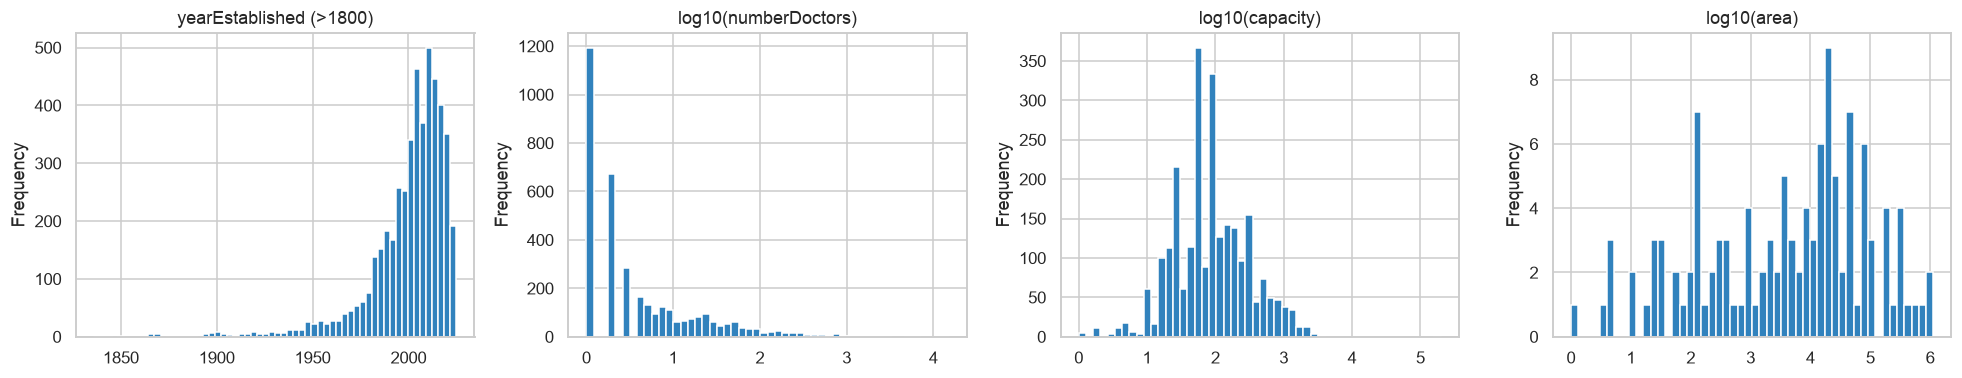

In [32]:
core_num = ['yearEstablished','numberDoctors','capacity','area']
display(fac[core_num].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.round(1))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
fac.yearEstablished[fac.yearEstablished > 1800].plot.hist(bins=60, ax=axes[0], color='#3182bd'); axes[0].set_title('yearEstablished (>1800)')
for ax, c in zip(axes[1:], ['numberDoctors','capacity','area']):
    np.log10(fac[c][fac[c] > 0]).plot.hist(bins=50, ax=ax, color='#3182bd'); ax.set_title(f'log10({c})')
plt.tight_layout(); plt.show()

In [33]:
# Implausible / suspicious values
YEAR_NOW = 2026
checks = {
  'yearEstablished == 0':            fac.yearEstablished == 0,
  'yearEstablished < 1800 (not 0)':  fac.yearEstablished.between(1, 1799),
  'yearEstablished > 2026':          fac.yearEstablished > YEAR_NOW,
  'numberDoctors == 0':              fac.numberDoctors == 0,
  'numberDoctors > 1000':            fac.numberDoctors > 1000,
  'capacity (beds) == 0':            fac.capacity == 0,
  'capacity > 3000 beds':            fac.capacity > 3000,
  'clinic with > 200 beds':          (fac.facilityTypeId=='clinic') & (fac.capacity > 200),
  'dentist with > 50 beds':          (fac.facilityTypeId=='dentist') & (fac.capacity > 50),
  '1 doctor but >= 100 beds':        (fac.numberDoctors==1) & (fac.capacity>=100),
  'non-integer doctors/beds':        (fac.numberDoctors % 1 > 0) | (fac.capacity % 1 > 0),
}
chk = pd.Series({k: int(v.sum()) for k, v in checks.items()}).to_frame('n_rows'); display(chk)
print('Largest capacity claims:'); display(fac.nlargest(8, 'capacity')[['name','address_city','facilityTypeId','capacity','numberDoctors']])
print('Largest numberDoctors claims:'); display(fac.nlargest(8, 'numberDoctors')[['name','address_city','facilityTypeId','capacity','numberDoctors']])
print('Oldest yearEstablished (>0):'); display(fac[fac.yearEstablished>0].nsmallest(6, 'yearEstablished')[['name','address_city','yearEstablished']])

,n_rows
yearEstablished == 0,3
yearEstablished < 1800 (not 0),4
yearEstablished > 2026,0
numberDoctors == 0,13
numberDoctors > 1000,11
capacity (beds) == 0,13
capacity > 3000 beds,2
clinic with > 200 beds,10
dentist with > 50 beds,0
1 doctor but >= 100 beds,72


Largest capacity claims:


,name,address_city,facilityTypeId,capacity,numberDoctors
6223,Harsh Hospital,Motihari,hospital,200000.0,NaN
237,"King George's Medical University, Lucknow",Lucknow,hospital,4000.0,1.0
64,"Krishna Institute of Medical Sciences, Hyderabad",Hyderabad,hospital,3000.0,1.0
36,Government Medical College And Hospital Chandrapur,Chandrapur,hospital,2844.0,NaN
471,Amrita Hospitals,Faridabad,hospital,2600.0,1.0
6462,Regional Mental Hospital Nagpur,Nagpur,hospital,2540.0,NaN
544,Kauvery Hospital,Chennai,hospital,2250.0,500.0
2159,Nectar Hospital,Patna,hospital,2200.0,155.0


Largest numberDoctors claims:


,name,address_city,facilityTypeId,capacity,numberDoctors
3537,Nithya Hospital,Dharmapuri,hospital,NaN,15000.0
408,Kims Hospital,Hyderabad,hospital,200.0,6000.0
2832,Scientific Pathology,Agra,hospital,NaN,5000.0
348,"Vijaya Diagnostic Centre - Main Road Gopalapatnam, Visakhapatnam",Visakhapatnam,clinic,NaN,3000.0
2370,"Megavision Diagnostic Centres, Pimpri",Pimpri-chinchwad,clinic,NaN,3000.0
9163,Narhari Hospital,Vadodara,hospital,200.0,2860.0
3193,Medall Diagnostics,Chennai,clinic,NaN,2500.0
185,Sahyadri Hospitals,Pune,hospital,900.0,2000.0


Oldest yearEstablished (>0):


,name,address_city,yearEstablished
169,Sri Krishna Hospital (Proddutur),Proddutur,7.0
2794,"Medini Cosmetic Surgery Centre, KPHB Colony",Hyderabad,15.0
8163,Changethu Ayurveda Hospital,Pathanamthitta,1723.0
6013,INHS Asvini,Mumbai,1756.0
7343,The Leprosy Mission Hospital & Home,Almora,1836.0
13,Civil Hospital,Ahmedabad,1841.0


In [34]:
# Value heaping: round numbers indicate estimates rather than counts
for c in ['capacity','numberDoctors']:
    s = fac[c].dropna(); s = s[s >= 10]
    print(f'{c}: share of values (>=10) divisible by 10 = {(s%10==0).mean()*100:.0f}% (expected ~10% if precise); by 50 = {(s%50==0).mean()*100:.0f}%')
print('Top capacity values:', fac.capacity.value_counts().head(12).to_dict())
print('Top numberDoctors values:', fac.numberDoctors.value_counts().head(12).to_dict())

capacity: share of values (>=10) divisible by 10 = 71% (expected ~10% if precise); by 50 = 47%
numberDoctors: share of values (>=10) divisible by 10 = 34% (expected ~10% if precise); by 50 = 15%
Top capacity values: {100.0: 300, 50.0: 261, 30.0: 111, 150.0: 100, 200.0: 95, 300.0: 93, 20.0: 84, 25.0: 80, 15.0: 67, 250.0: 57, 40.0: 57, 10.0: 56}
Top numberDoctors values: {1.0: 1194, 2.0: 673, 3.0: 283, 4.0: 163, 5.0: 132, 6.0: 92, 10.0: 66, 7.0: 62, 8.0: 61, 9.0: 43, 14.0: 35, 20.0: 34}


,numberDoctors,capacity,yearEstablished,numberDoctors_n,capacity_n
facilityTypeId,,,,,
clinic,1.0,25.0,2009.0,1269,124
dentist,2.0,4.0,2010.0,175,4
doctor,1.5,NaN,2006.0,4,0
farmacy,1.0,NaN,1984.0,1,0
hospital,5.0,100.0,2003.0,2177,2382
nursing_home,1.0,NaN,NaN,1,0
pharmacy,NaN,NaN,NaN,0,0


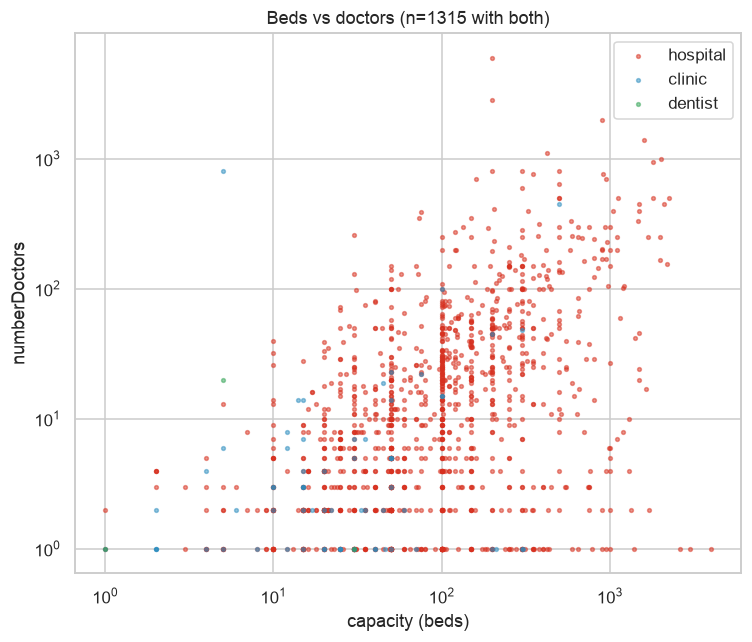

Beds per doctor (median): 7.1


In [35]:
# Scale by facility type
display(fac.groupby('facilityTypeId')[['numberDoctors','capacity','yearEstablished']].median().join(
        fac.groupby('facilityTypeId')[['numberDoctors','capacity']].count().add_suffix('_n')))
m = (fac.numberDoctors > 0) & (fac.capacity > 0)
fig, ax = plt.subplots(figsize=(7, 6))
for t, col in zip(['hospital','clinic','dentist'], ['#d7301f','#2b8cbe','#31a354']):
    mm = m & (fac.facilityTypeId == t)
    ax.scatter(fac.loc[mm,'capacity'], fac.loc[mm,'numberDoctors'], s=6, alpha=.5, c=col, label=t)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('capacity (beds)'); ax.set_ylabel('numberDoctors'); ax.legend()
ax.set_title(f'Beds vs doctors (n={m.sum()} with both)'); plt.tight_layout(); plt.show()
print('Beds per doctor (median):', (fac.capacity/fac.numberDoctors)[m].median().round(1))

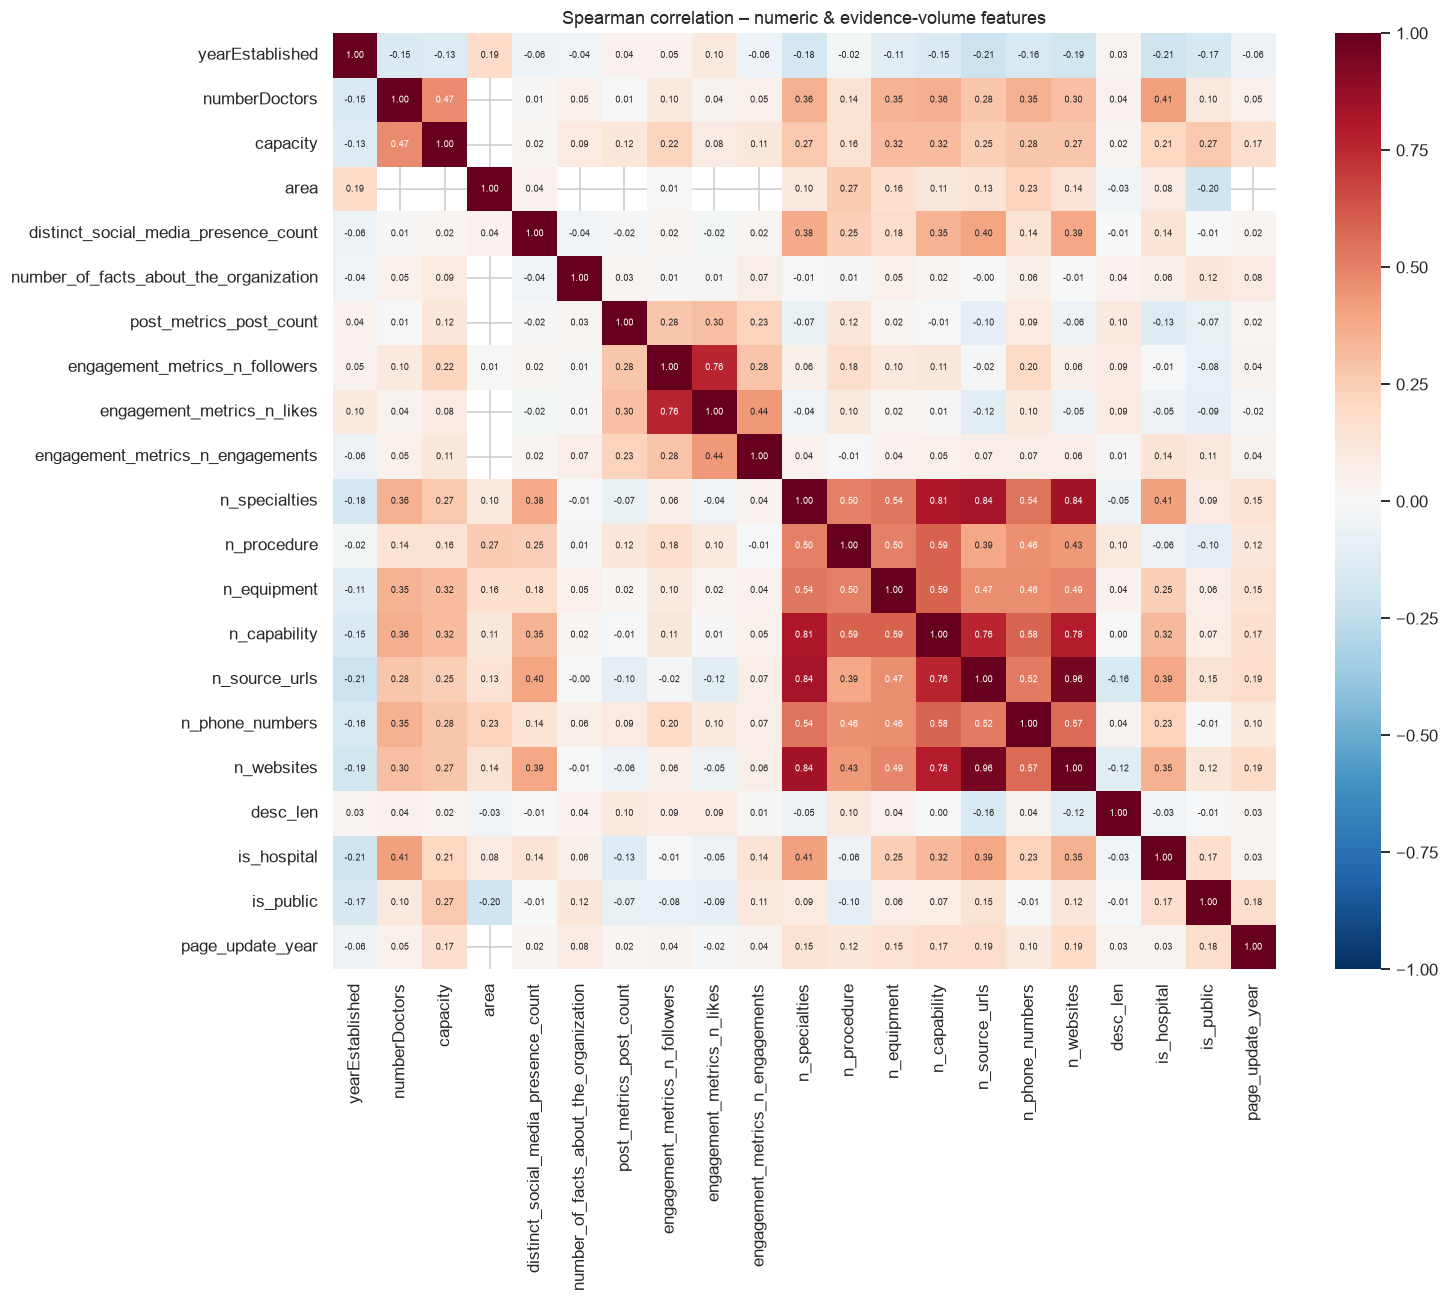

Strongest positive:
n_source_urls                   n_websites                    0.96
n_specialties                   n_websites                    0.84
                                n_source_urls                 0.84
                                n_capability                  0.81
n_capability                    n_websites                    0.78
engagement_metrics_n_followers  engagement_metrics_n_likes    0.76
n_capability                    n_source_urls                 0.76
n_equipment                     n_capability                  0.59
n_procedure                     n_capability                  0.59
n_capability                    n_phone_numbers               0.58
n_phone_numbers                 n_websites                    0.57
n_specialties                   n_phone_numbers               0.54

Strongest negative:
yearEstablished  n_source_urls   -0.21
                 is_hospital     -0.21
area             is_public       -0.20
yearEstablished  n_websites      -0.19

In [36]:
# Correlations: numeric fields + evidence-volume features (Spearman, robust to heavy tails)
feat = fac[NUM_COLS].copy().drop(columns=['latitude','longitude'])
for c in ['specialties','procedure','equipment','capability','source_urls','phone_numbers','websites']:
    feat[f'n_{c}'] = lens[c]
feat['desc_len'] = fac.description.str.len()
feat['is_hospital'] = (fac.facilityTypeId == 'hospital').astype(float)
feat['is_public'] = fac.operatorTypeId.isin(['public','government']).astype(float)
feat['page_update_year'] = fac.recency_of_page_update.dt.year
corr = feat.corr(method='spearman', min_periods=100)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size':6}, ax=ax)
ax.set_title('Spearman correlation – numeric & evidence-volume features'); plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print('Strongest positive:'); print(pairs.sort_values(ascending=False).head(12).round(2).to_string())
print('\nStrongest negative:'); print(pairs.sort_values().head(6).round(2).to_string())

## 10. Dates, social media & engagement

recency_of_page_update: n=3,526  min=2003-09-04  median=2025-05-18  max=2027-07-20  future (> 2026-11-21)=1
post_metrics_most_recent_social_media_post_date: n=4,907  min=2009-06-29  median=2023-07-25  max=2026-01-22  future (> 2026-11-21)=0


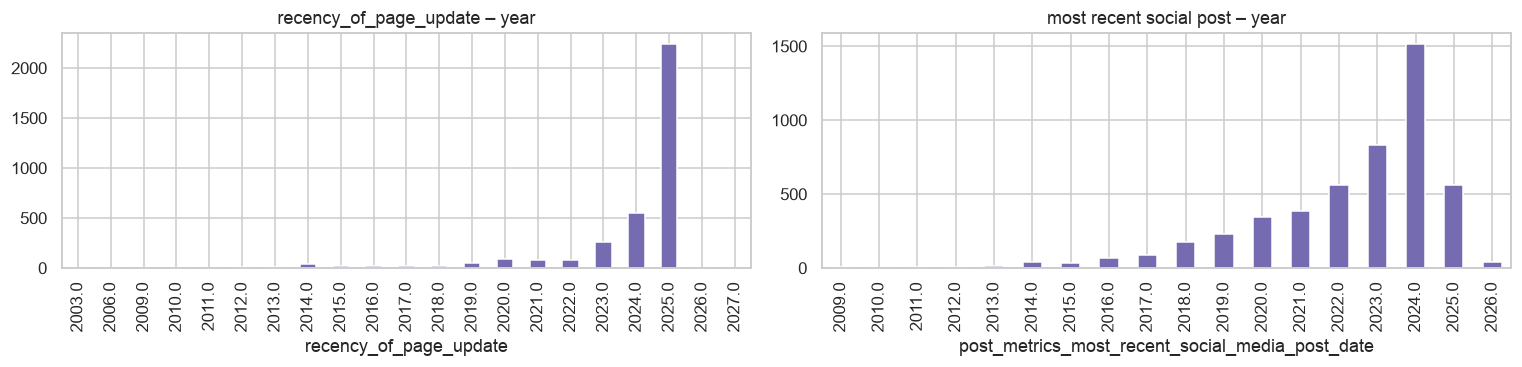

Facilities whose last social post was before 2024 (possibly inactive/closed): 2,793


In [37]:
for c in DATE_COLS:
    s = fac[c].dropna()
    print(f'{c}: n={len(s):,}  min={s.min().date()}  median={s.median().date()}  max={s.max().date()}  '
          f'future (> 2026-11-21)={int((s > "2026-11-21").sum())}')
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
fac.recency_of_page_update.dt.year.value_counts().sort_index().plot.bar(ax=axes[0], color='#756bb1'); axes[0].set_title('recency_of_page_update – year')
fac.post_metrics_most_recent_social_media_post_date.dt.year.value_counts().sort_index().plot.bar(ax=axes[1], color='#756bb1'); axes[1].set_title('most recent social post – year')
plt.tight_layout(); plt.show()
stale = fac.post_metrics_most_recent_social_media_post_date < '2024-01-01'
print(f'Facilities whose last social post was before 2024 (possibly inactive/closed): {stale.sum():,}')

In [38]:
eng = ['engagement_metrics_n_followers','engagement_metrics_n_likes','engagement_metrics_n_engagements','post_metrics_post_count','number_of_facts_about_the_organization']
display(fac[eng].describe(percentiles=[.5,.9,.99]).T.round(0))
print('Zero followers:', (fac.engagement_metrics_n_followers == 0).sum(), '| zero posts:', (fac.post_metrics_post_count == 0).sum())
print('Top followers:'); display(fac.nlargest(6, 'engagement_metrics_n_followers')[['name','address_city','engagement_metrics_n_followers']])
print('-> Big followings belong to chains / brand pages, not the specific branch: a popularity signal, NOT a quality signal.')

,count,mean,std,min,50%,90%,99%,max
engagement_metrics_n_followers,8873.0,8066.0,244709.0,0.0,245.0,2600.0,35533.0,15000000.0
engagement_metrics_n_likes,7789.0,1194.0,7272.0,0.0,69.0,1800.0,18000.0,384000.0
engagement_metrics_n_engagements,4877.0,156.0,2097.0,0.0,0.0,93.0,2778.0,121855.0
post_metrics_post_count,3774.0,44.0,1369.0,0.0,0.0,3.0,275.0,59000.0
number_of_facts_about_the_organization,2755.0,7.0,14.0,0.0,5.0,10.0,31.0,442.0


Zero followers: 1190 | zero posts: 2511
Top followers:


,name,address_city,engagement_metrics_n_followers
229,J J Eye Hospital,Mumbai,15000000.0
3124,Shiromany Dental Care,Agra,15000000.0
250,Kidwai Memorial Institute of Oncology,Bengaluru,4756342.0
287,Fortis Hospital,Bangalore,4756342.0
8178,Shankar Super Speciality Hospital,Bangalore,4756342.0
1219,Sher-I-Kashmir Institute of Medical Sciences,Srinagar,1751900.0


-> Big followings belong to chains / brand pages, not the specific branch: a popularity signal, NOT a quality signal.


## 11. Contact info & provenance

In [39]:
ph = fac.phone_numbers.dropna().explode().dropna().astype(str)
print(f'Phone entries: {len(ph):,} | distinct: {ph.nunique():,}')
print('Formats:', ph.str.replace(r'\d', '9', regex=True).value_counts().head(6).to_dict())
fac['n_distinct_phones'] = fac.phone_numbers.map(lambda l: len(set(l)) if isinstance(l, list) else 0)
print('Distinct phones per facility:', fac.n_distinct_phones.describe().round(1).to_dict())
off_in = fac.apply(lambda r: isinstance(r.phone_numbers, list) and r.officialPhone in r.phone_numbers, axis=1)
print(f'officialPhone contained in phone_numbers: {off_in[fac.officialPhone.notna()].mean()*100:.1f}%')
shared_phone = ph.groupby(ph).size()
print('Same phone number appearing in >1 facility record:', (fac.officialPhone.value_counts() > 1).sum(), 'official numbers')

em = fac.email.dropna().str.lower().str.split('@').str[-1]
print('\nEmail domains:', em.value_counts().head(8).to_dict())
print(f"'[email protected]' = Cloudflare email-obfuscation scraped verbatim -> {int((fac.email.str.contains('protected', na=False)).sum())} invalid emails")
print(f'Free-mail (gmail/yahoo/hotmail/rediff) share: {em.isin(["gmail.com","yahoo.com","hotmail.com","rediffmail.com","yahoo.co.in","outlook.com"]).mean()*100:.0f}%')

Phone entries: 96,573 | distinct: 37,162
Formats: {'+999999999999': 94902, '+9999999999999': 901, '99999999999': 645, '+99999999999': 65, '+9999999999': 29, '+99999999999999': 18}
Distinct phones per facility: {'count': 9989.0, 'mean': 4.0, 'std': 4.1, 'min': 0.0, '25%': 2.0, '50%': 3.0, '75%': 5.0, 'max': 48.0}


officialPhone contained in phone_numbers: 99.7%
Same phone number appearing in >1 facility record: 104 official numbers

Email domains: {'gmail.com': 4730, '[email\xa0protected]': 349, 'yahoo.com': 284, 'yahoo.co.in': 109, 'hotmail.com': 86, 'rediffmail.com': 70, 'yahoo.in': 30, 'ymail.com': 16}
'[email protected]' = Cloudflare email-obfuscation scraped verbatim -> 363 invalid emails
Free-mail (gmail/yahoo/hotmail/rediff) share: 62%


Source URLs: 158,444 | distinct domains: 12,144


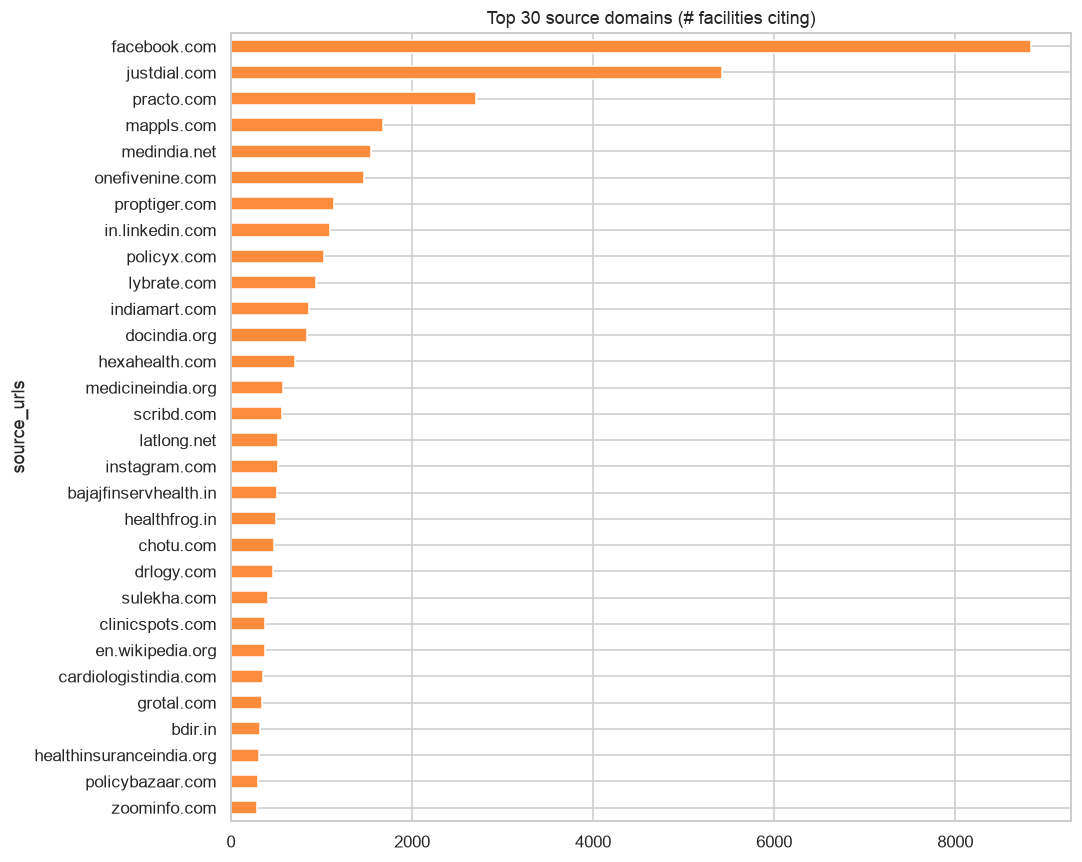

Records sourced ONLY from aggregators/social sites: 2 (0%)
Records where the facility's own website is among sources: 4,735 (47%)
Distinct source domains per facility: {'count': 9989.0, 'mean': 7.7, 'std': 5.3, 'min': 0.0, '25%': 4.0, '50%': 6.0, '75%': 10.0, 'max': 50.0}


Records with at least one .gov.in / nic.in source: 1,013


In [40]:
def domain(u):
    try:
        u = u if '://' in u else 'http://' + u
        return urlparse(u).netloc.lower().removeprefix('www.')
    except Exception: return None
urls = fac.source_urls.dropna().explode().dropna().astype(str)
doms = urls.map(domain)
dom_fac = fac.source_urls.dropna().map(lambda l: {domain(u) for u in l}).explode().value_counts()
print(f'Source URLs: {len(urls):,} | distinct domains: {doms.nunique():,}')
fig, ax = plt.subplots(figsize=(10, 8))
dom_fac.head(30).plot.barh(ax=ax, color='#fd8d3c'); ax.invert_yaxis(); ax.set_title('Top 30 source domains (# facilities citing)'); plt.tight_layout(); plt.show()

AGG = ['justdial.com','practo.com','facebook.com','instagram.com','linkedin.com','lybrate.com','sehat.com','credihealth.com',
       'medindia.net','zaubacorp.com','latlong.net','google.com','youtube.com','x.com','twitter.com','indiamart.com','hexahealth.com',
       'quickerala.com','bajajfinservhealth.in','medicineindia.org','askapollo.com','clinicspots.com','vaidam.com']
fac['n_source_domains'] = fac.source_urls.map(lambda l: len({domain(u) for u in l}) if isinstance(l, list) else 0)
fac['has_own_site_source'] = fac.apply(lambda r: isinstance(r.source_urls, list) and pd.notna(r.officialWebsite) and
                                        any(domain(r.officialWebsite) == domain(u) for u in r.source_urls), axis=1)
only_agg = fac.source_urls.map(lambda l: isinstance(l, list) and all(any(a in (domain(u) or '') for a in AGG) for u in l))
print(f'Records sourced ONLY from aggregators/social sites: {only_agg.sum():,} ({only_agg.mean()*100:.0f}%)')
print(f'Records where the facility\'s own website is among sources: {fac.has_own_site_source.sum():,} ({fac.has_own_site_source.mean()*100:.0f}%)')
print('Distinct source domains per facility:', fac.n_source_domains.describe().round(1).to_dict())
gov = fac.source_urls.map(lambda l: isinstance(l, list) and any(('.gov.in' in (domain(u) or '')) or ('nic.in' in (domain(u) or '')) for u in l))
print(f'Records with at least one .gov.in / nic.in source: {gov.sum():,}')

## 12. Free-text description

Description length (chars): {'count': 9989.0, 'mean': 179.0, 'std': 205.0, 'min': 5.0, '5%': 21.0, '50%': 115.0, '95%': 535.0, 'max': 6557.0}
Description == name (no real description): 158
Descriptions < 40 chars: 1206
Duplicate (boilerplate) descriptions shared by >1 facility: 569


,n
description,
Hospital,40
Open 24 Hrs,34
Dental Clinic,30
Providing exceptional cardiac care to the community,22
Diagnostic Center,14


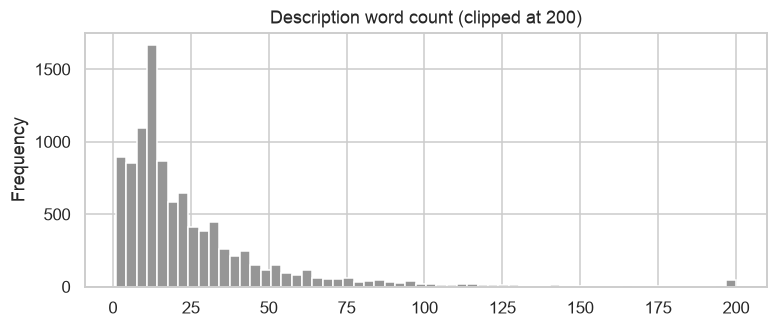

Descriptions containing non-Latin script (Hindi etc.): 42


In [41]:
dl = fac.description.str.len(); wc = fac.description.str.split().str.len()
print('Description length (chars):', dl.describe(percentiles=[.05,.5,.95]).round(0).to_dict())
print('Description == name (no real description):', (fac.description.str.strip().str.lower() == fac.name.str.strip().str.lower()).sum())
print('Descriptions < 40 chars:', (dl < 40).sum())
print('Duplicate (boilerplate) descriptions shared by >1 facility:', fac.description.duplicated(keep=False).sum())
display(fac.description.value_counts().head(5).to_frame('n'))
fig, ax = plt.subplots(figsize=(8, 3)); wc.clip(upper=200).plot.hist(bins=60, ax=ax, color='#969696'); ax.set_title('Description word count (clipped at 200)'); plt.show()
non_ascii = fac.description.str.contains(r'[^\x00-\x7F‘-”–—•₹]', regex=True)
print('Descriptions containing non-Latin script (Hindi etc.):', non_ascii.sum())

## 13. Duplicates, merged and contradictory records

The brief warns: *"Some records merge two hospitals, some have contradictory locations, and some list services with almost nothing to back them up."* We quantify each.

In [42]:
# 13a. Duplicates
nm = fac.name.str.lower().str.replace(r'[^a-z0-9 ]', '', regex=True).str.strip()
print('Exact duplicate name (any city):', nm.duplicated(keep=False).sum())
key = nm + '|' + fac.address_city.str.lower().str.strip()
print('Duplicate name + city:', key.duplicated(keep=False).sum())
cid = fac.cluster_id.dropna()
print(f'Duplicate cluster_id (excluding the 30 truncated rows with no cluster_id): {cid.duplicated(keep=False).sum()} -> cluster_id is a usable unique entity key once exact-duplicate rows are dropped')
dn = fac[key.duplicated(keep=False)].sort_values('name')
display(dn[['name','address_city','pin6','latitude','longitude','facilityTypeId']].head(12))
print('Most frequent names (chains vs generic names):'); print(fac.name.value_counts().head(12).to_dict())

Exact duplicate name (any city): 831
Duplicate name + city: 12
Duplicate cluster_id (excluding the 30 truncated rows with no cluster_id): 0 -> cluster_id is a usable unique entity key once exact-duplicate rows are dropped


,name,address_city,pin6,latitude,longitude,facilityTypeId
226,Care Dental Hospital,Bangalore,560032,13.007463,77.570999,hospital
2643,Care Dental Hospital,Bangalore,560070,12.919208,77.557816,clinic
9,"Government Medical College, Thiruvananthapuram",Thiruvananthapuram,695009,9.408110,76.347427,hospital
8533,"Government Medical College, Thiruvananthapuram",Thiruvananthapuram,695011,8.523643,76.928284,hospital
1196,Om Dental Clinic,Ahmedabad,380043,23.038357,72.496178,dentist
8409,Om Dental Clinic,Ahmedabad,361006,23.573288,70.647751,clinic
1331,Rajindra Hospital Patiala,Patiala,147001,30.328777,76.384338,hospital
137,"Rajindra Hospital, Patiala",Patiala,147001,30.332602,76.381882,hospital
611,Sarla Hospital,Mumbai,400054,19.085762,72.836761,hospital
8311,Sarla Hospital,Mumbai,400054,20.923336,77.752655,hospital


Most frequent names (chains vs generic names):
{'Apollo Clinic': 10, 'City Hospital': 8, 'Life Care Hospital': 6, 'Bansal Hospital': 5, 'Fortis Hospital': 5, 'Ankur Hospital': 5, 'Surya Hospital': 5, 'Pathkind Labs': 5, 'Balaji Hospital': 5, 'Sanjivani Hospital': 5, 'ESI Hospital': 5, 'Prasad Hospital': 5}


In [43]:
# 13b. Showcase: a clearly merged record
r = fac.iloc[0]
print('NAME:', r['name'], '| city:', r['address_city'], '| state:', r['address_stateOrRegion'], '| PIN:', r['pin6'],
      f"(PIN says {r['pin_state']}/{r['pin_district']})", '| coords:', (round(r.latitude,3), round(r.longitude,3)), f"{r.km_to_pin:.0f} km from PIN")
print('capacity:', r.capacity, '| doctors:', r.numberDoctors, '| distinct phones:', r.n_distinct_phones)
print('Capability snippets:')
for x in r['capability'][:6]: print('  -', x)
print('-> An eye hospital in Hyderabad, with a Delhi PIN, Pondicherry coordinates, dialysis units and 1241-bed oxygen pipelines: merged from many sources.')

NAME: Aravind Eye Hospital | city: Hyderabad | state: Telangana | PIN: 110002 (PIN says DELHI/CENTRAL) | coords: (np.float64(11.938), np.float64(79.485)) 1871 km from PIN
capacity: 650.0 | doctors: 1.0 | distinct phones: 33
Capability snippets:
  - Eye care hospital
  - Located in Hyderabad
  - Aravind Eye Hospital Pvt. Ltd. is listed in the Hyderabad hospital directory as Aravind Eye Hospital
  - Madras Medical Mission, Chennai is listed as a referral hospital outside the State.
  - Janakpuri Super Speciality Hospital is listed under 'Society Hospitals' in the Delhi Government Hospitals network.
  - Listed as a Delhi Government Hospital under the Delhi Government Hospitals category on the Health & Family Welfare website.
-> An eye hospital in Hyderabad, with a Delhi PIN, Pondicherry coordinates, dialysis units and 1241-bed oxygen pipelines: merged from many sources.


,n,%
any_list_hit_50_cap,3220,32.2
no_equipment_evidence,2878,28.8
coords_>50km_from_PIN,1562,15.6
clinic/dentist_claims_heavy_services,567,5.7
PIN_missing_or_invalid,289,2.9
>20_distinct_phones,122,1.2
implausible_numbers,121,1.2
state_vs_PIN_conflict,65,0.7
truncated_record,30,0.3
coords_outside_India,6,0.1


Red flags per facility (excluding no_equipment): {0: 5369, 1: 3441, 2: 1016, 3: 146, 4: 14, 5: 3}


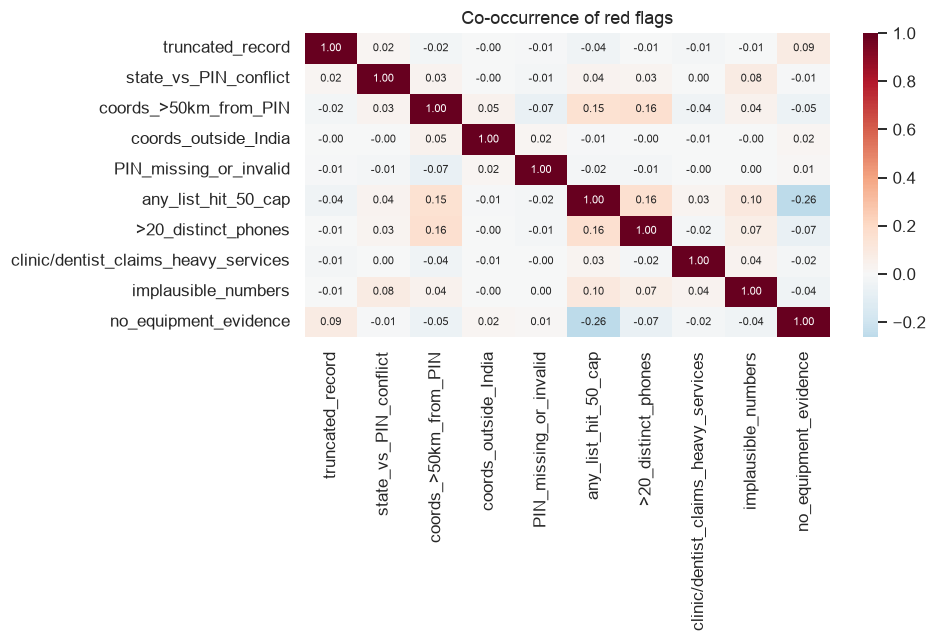

In [44]:
# 13c. Heuristic red flags per facility
SERVICE_HEAVY = r'cardiac surgery|cabg|bypass|neurosurg|icu|intensive care|dialysis|transplant|cath ?lab|nicu|c-section|caesarean|cesarean'
offer_text = fac[['procedure','capability','equipment']].apply(lambda r: ' '.join(' '.join(map(str, v)) for v in r if isinstance(v, list)).lower(), axis=1)
flags = pd.DataFrame({
  'truncated_record':          truncated.values,
  'state_vs_PIN_conflict':     fac.state_pin_conflict,
  'coords_>50km_from_PIN':     fac.km_to_pin > 50,
  'coords_outside_India':      fac.latitude.notna() & ~in_india(fac.latitude, fac.longitude),
  'PIN_missing_or_invalid':    ~fac.pin_in_directory,
  'any_list_hit_50_cap':       (lens[['specialties','procedure','equipment','capability']] == 50).any(axis=1),
  '>20_distinct_phones':       fac.n_distinct_phones > 20,
  'clinic/dentist_claims_heavy_services': fac.facilityTypeId.isin(['clinic','dentist','doctor']) & offer_text.str.contains(SERVICE_HEAVY),
  'implausible_numbers':       pd.concat(checks.values(), axis=1).any(axis=1),
  'no_equipment_evidence':     nofo.equipment,
})
fs = flags.sum().sort_values(ascending=False).to_frame('n'); fs['%'] = (fs.n/len(fac)*100).round(1); display(fs)
fac['n_red_flags'] = flags.drop(columns=['no_equipment_evidence']).sum(axis=1)
print('Red flags per facility (excluding no_equipment):', fac.n_red_flags.value_counts().sort_index().to_dict())
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(flags.astype(int).corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size':7}); ax.set_title('Co-occurrence of red flags'); plt.tight_layout(); plt.show()

In [45]:
# Do merged-looking records (lists at cap) have more geographic contradictions? -> evidence that list-size = merge signal
g = flags.groupby('any_list_hit_50_cap')[['state_vs_PIN_conflict','coords_>50km_from_PIN','>20_distinct_phones']].mean().mul(100).round(1)
g.index = ['lists below cap', 'some list at 50 cap']; g

,state_vs_PIN_conflict,coords_>50km_from_PIN,>20_distinct_phones
lists below cap,0.4,11.8,0.0
some list at 50 cap,1.1,23.8,3.7


## 14. Service-claim coverage for challenge services

For each service in the brief we search every evidence field with a keyword pattern, and measure **evidence depth** = how many *independent fields* mention it (specialties / procedure / equipment / capability / description). A service mentioned in 1 field is a weak claim; mentioned in 3+ fields, plus equipment, is much stronger.

In [46]:
SERVICES = {
 'dialysis':        r'dialysis|haemodialysis|hemodialysis|nephrolog',
 'c_section':       r'c-section|c section|caesarean|cesarean|lscs',
 'obstetrics/delivery': r'obstetric|gynecologyandobstetrics|maternity|labou?r room|delivery|childbirth',
 'nicu':            r'\bnicu\b|neonatal intensive|neonatology|neonatologyperinatal',
 'icu':             r'\bicu\b|intensive care|critical care|criticalcare',
 'cardiac_surgery': r'cardiac surg|cardiothoracic|\bcabg\b|bypass surg|open heart|cardiacsurgery|valve replace',
 'cath_lab':        r'cath ?lab|angioplast|angiograph',
 'mri':             r'\bmri\b|magnetic resonance',
 'ct_scan':         r'\bct\b|ct scan|computed tomography',
 'burn_care':       r'\bburns?\b|burnandtrauma',
 'trauma/emergency':r'trauma|emergency|casualty|accident',
 'blood_bank':      r'blood bank|blood storage',
 'oncology':        r'oncolog|chemotherapy|radiotherapy|cancer',
 'ventilator':      r'ventilator',
}
FIELDS = ['specialties','procedure','equipment','capability','description']
ftext = {f: (fac[f].map(lambda v: ' '.join(map(str, v)) if isinstance(v, list) else '') if f != 'description' else fac.description.fillna('')).str.lower()
         for f in FIELDS}
hit = {s: pd.DataFrame({f: ftext[f].str.contains(p, regex=True) for f in FIELDS}) for s, p in SERVICES.items()}
cov = pd.DataFrame({s: h.sum() for s, h in hit.items()}).T
cov['any_field'] = [h.any(axis=1).sum() for h in hit.values()]
cov['only_1_field'] = [(h.sum(axis=1) == 1).sum() for h in hit.values()]
cov['3plus_fields'] = [(h.sum(axis=1) >= 3).sum() for h in hit.values()]
cov['pct_weak'] = (cov.only_1_field/cov.any_field*100).round(0)
cov.sort_values('any_field', ascending=False)

,specialties,procedure,equipment,capability,description,any_field,only_1_field,3plus_fields,pct_weak
obstetrics/delivery,4528,1212,459,2552,465,4935,2233,1242,45.0
trauma/emergency,2492,1408,290,3492,544,4232,1556,1064,37.0
icu,1860,243,910,2117,299,2925,1226,663,42.0
oncology,2224,1345,181,1519,324,2846,1208,804,42.0
dialysis,2200,796,475,1322,212,2483,1027,729,41.0
nicu,1290,130,243,899,119,1562,769,269,49.0
ct_scan,0,803,1398,520,115,1532,643,363,42.0
cardiac_surgery,760,443,28,347,29,983,559,182,57.0
mri,0,453,885,334,68,950,412,221,43.0
cath_lab,2,615,526,281,41,847,389,148,46.0


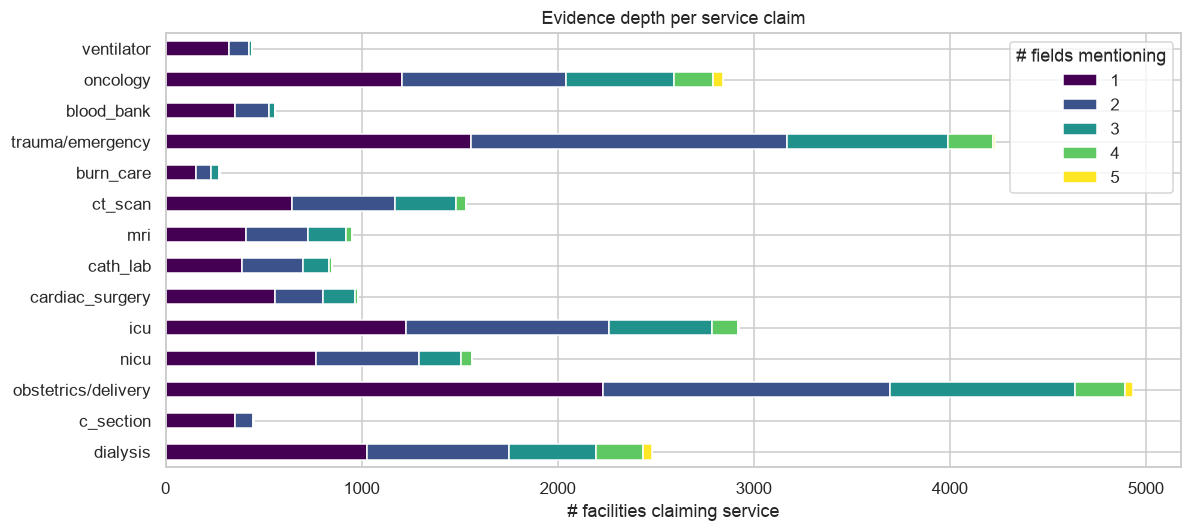

In [47]:
depth = pd.DataFrame({s: h.sum(axis=1) for s, h in hit.items()})
fig, ax = plt.subplots(figsize=(11, 5))
dd_ = depth.apply(lambda c: c[c > 0].value_counts().sort_index()).T.fillna(0)
dd_.plot.barh(stacked=True, ax=ax, colormap='viridis'); ax.set_xlabel('# facilities claiming service'); ax.legend(title='# fields mentioning')
ax.set_title('Evidence depth per service claim'); plt.tight_layout(); plt.show()

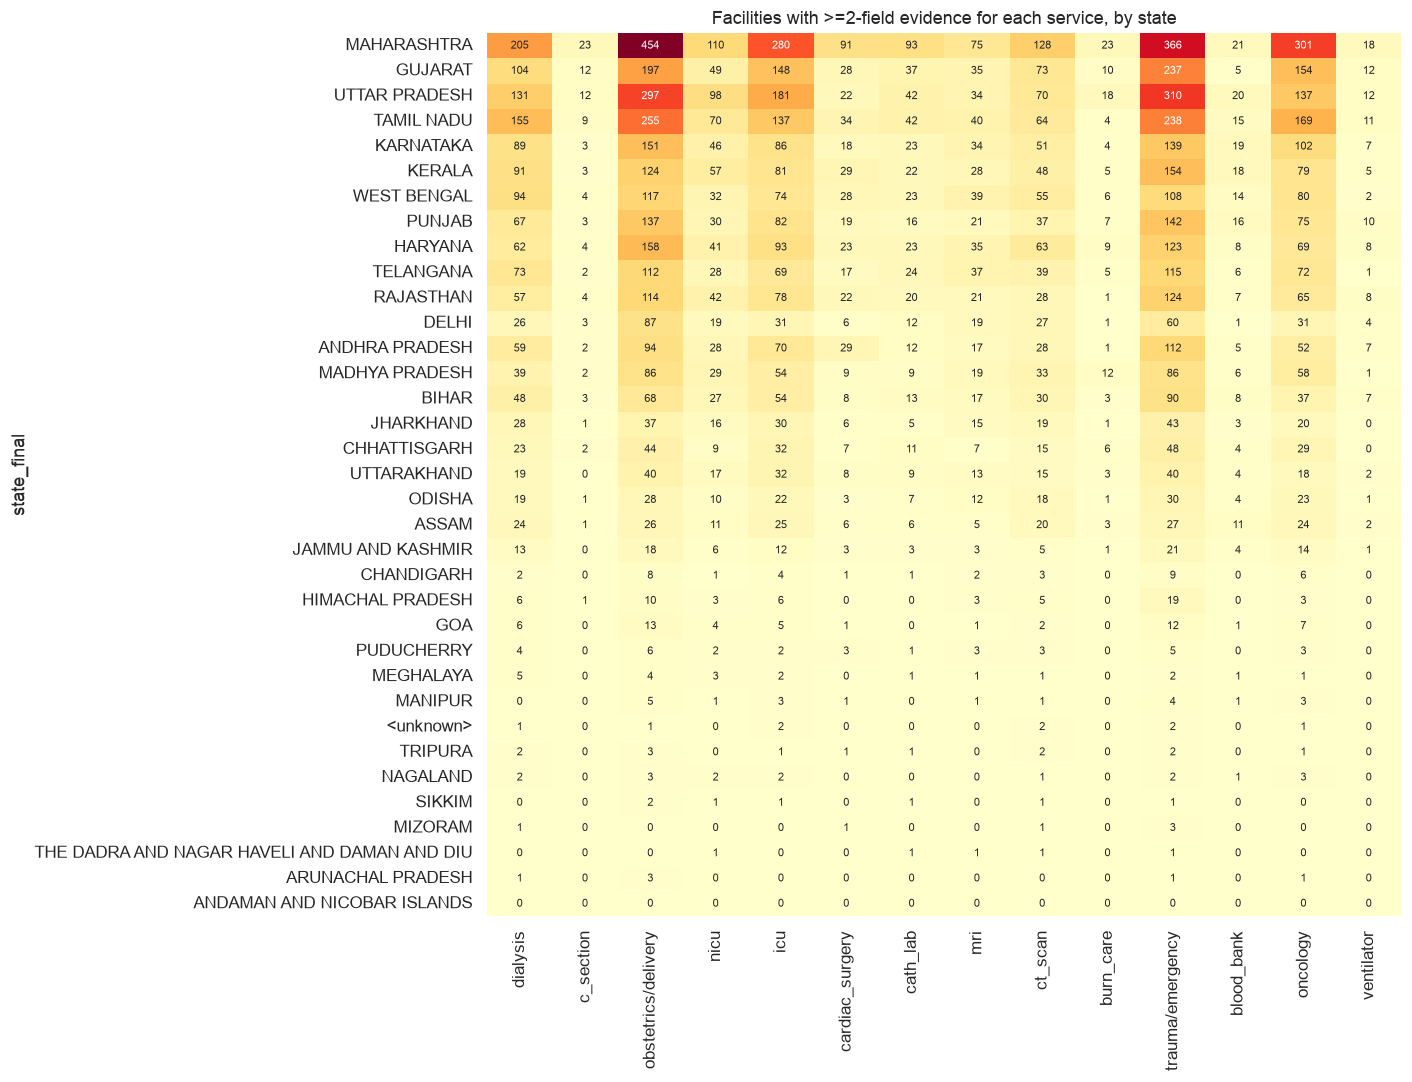

In [48]:
# Geography of claims: facilities per state for key services (only claims with >=2 fields of evidence)
strong = depth >= 2
geo = strong.groupby(fac.state_final.fillna('<unknown>')).sum()
geo['ALL_facilities'] = fac.state_final.fillna('<unknown>').value_counts()
geo = geo.sort_values('ALL_facilities', ascending=False)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(geo.drop(columns='ALL_facilities'), annot=True, fmt='d', cmap='YlOrRd', ax=ax, annot_kws={'size':7}, cbar=False)
ax.set_title('Facilities with >=2-field evidence for each service, by state'); plt.tight_layout(); plt.show()

In [49]:
# Service claims by facility type – sanity check (dentists claiming dialysis = suspicious)
by_t = strong.groupby(fac.facilityTypeId.fillna('<null>')).mean().mul(100).round(1)
by_t.insert(0, 'n', fac.facilityTypeId.fillna('<null>').value_counts()); by_t.sort_values('n', ascending=False)

,n,dialysis,c_section,obstetrics/delivery,nicu,icu,cardiac_surgery,cath_lab,mri,ct_scan,burn_care,trauma/emergency,blood_bank,oncology,ventilator
facilityTypeId,,,,,,,,,,,,,,,
hospital,5626,24.0,1.4,40.6,13.2,28.8,7.2,6.9,6.6,11.5,2.0,41.3,3.5,24.5,2.0
clinic,3782,2.7,0.4,10.8,1.4,2.0,0.6,1.9,4.3,6.1,0.3,7.9,0.2,6.3,0.2
dentist,490,0.0,0.0,0.4,0.0,0.0,0.0,0.0,0.0,1.4,0.0,10.6,0.0,3.3,0.0
<null>,57,0.0,0.0,1.8,0.0,1.8,0.0,0.0,3.5,3.5,0.0,1.8,3.5,3.5,0.0
doctor,21,0.0,0.0,9.5,0.0,0.0,0.0,0.0,4.8,4.8,0.0,4.8,0.0,4.8,0.0
farmacy,10,0.0,0.0,30.0,0.0,0.0,0.0,0.0,10.0,10.0,0.0,0.0,0.0,10.0,0.0
pharmacy,2,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
nursing_home,1,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [50]:
# How good is the 'specialties' controlled vocabulary vs free text? e.g. nephrology specialty vs dialysis text
neph = fac.specialties.map(lambda l: isinstance(l, list) and 'nephrology' in l)
dial_txt = hit['dialysis'][['procedure','equipment','capability']].any(axis=1)
print(pd.crosstab(neph.rename('nephrology in specialties'), dial_txt.rename('dialysis in procedure/equipment/capability'), margins=True))
print('\n-> Specialty codes and free-text evidence disagree often; use both, weight concrete equipment/procedure text higher.')

dialysis in procedure/equipment/capability  False  True   All
nephrology in specialties                                    
False                                        7543   293  7836
True                                          826  1327  2153
All                                          8369  1620  9989

-> Specialty codes and free-text evidence disagree often; use both, weight concrete equipment/procedure text higher.


## 15. India Post PIN code directory

In [51]:
print(pin.shape); display(pin.head(3))
print('Nulls:', pin.isna().sum().to_dict())
print('Literal "NA" coordinates count as null after numeric coercion -> lat missing:', pin.lat.isna().sum(), '| lon missing:', pin.lon.isna().sum())
bad = pin.lat.notna() & ~in_india(pin.lat, pin.lon)
print(f'Coordinates present but outside India / garbage: {bad.sum():,}  e.g.', pin.loc[bad, ['latitude','longitude']].head(5).values.tolist())
print('officetype:', pin.officetype.value_counts().to_dict(), '| delivery:', pin.delivery.value_counts().to_dict())
print(f'Distinct PINs: {pin.pincode.nunique():,} | districts: {pin.district.nunique()} | states: {pin.statename.nunique()} | circles: {pin.circlename.nunique()}')
print('PINs spanning >1 state:', (pin_nstates > 1).sum(), '| PINs spanning >1 district:', (pin.groupby("pincode").district.nunique() > 1).sum())
print('Offices per PIN:', pin.groupby('pincode').size().describe().round(1).to_dict())
med = pin_ok.groupby('pincode')[['lat','lon']].transform('median')
d_off = pd.Series(haversine_km(pin_ok.lat, pin_ok.lon, med.lat, med.lon), index=pin_ok.index)
print('Office distance to its PIN median centroid (km):', d_off.describe(percentiles=[.5,.9,.99]).round(1).to_dict())
print('Per-PIN median office distance (km):', d_off.groupby(pin_ok.pincode).median().describe(percentiles=[.5,.9,.99]).round(1).to_dict())
print('-> Median PIN centroids are robust (~2-3 km typical), so a facility >50 km from its PIN centroid is a genuine inconsistency, not directory noise.')

(165627, 13)


,circlename,regionname,divisionname,officename,pincode,officetype,delivery,district,statename,latitude,longitude,lat,lon
0,Telangana Circle,Hyderabad Region,Adilabad Division,Kothimir B.O,504273,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.3638689,79.5376658,19.363869,79.537666
1,Telangana Circle,Hyderabad Region,Adilabad Division,Papanpet B.O,504299,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,19.4764899,79.5839230,19.476490,79.583923
2,Telangana Circle,Hyderabad Region,Adilabad Division,Kukuda B.O,504299,BO,Delivery,KUMURAM BHEEM ASIFABAD,TELANGANA,NaN,NaN,NaN,NaN


Nulls: {'circlename': 0, 'regionname': 315, 'divisionname': 0, 'officename': 0, 'pincode': 0, 'officetype': 0, 'delivery': 0, 'district': 715, 'statename': 715, 'latitude': 12007, 'longitude': 12002, 'lat': 12013, 'lon': 12008}
Literal "NA" coordinates count as null after numeric coercion -> lat missing: 12013 | lon missing: 12008
Coordinates present but outside India / garbage: 2,613  e.g. [['79.0000000', '17.0000000'], ['35.8968000', '61.2536900'], ['39.5698000', '58.6359000'], ['18.1690283', '18.1690283'], ['83.5297000', '18.6149000']]
officetype: {'BO': 140270, 'PO': 24546, 'HO': 811} | delivery: {'Delivery': 157901, 'Non Delivery': 7726}
Distinct PINs: 19,586 | districts: 749 | states: 36 | circles: 24
PINs spanning >1 state: 52 | PINs spanning >1 district: 1258
Offices per PIN: {'count': 19586.0, 'mean': 8.5, 'std': 7.3, 'min': 1.0, '25%': 3.0, '50%': 7.0, '75%': 11.0, 'max': 153.0}
Office distance to its PIN median centroid (km): {'count': 151001.0, 'mean': 26.8, 'std': 114.3, '

## 16. NFHS-5 district health indicators

NFHS conventions: `*` = suppressed (fewer than 25 unweighted cases), `(x)` = based on 25–49 unweighted cases (**low reliability**). These are *not* nulls in the CSV and force columns to text.

In [52]:
nf_raw = pd.read_csv(f'{DATA}/nfhs_5_district_health_indicators.csv', dtype=str)
print(nf_raw.shape, '| districts:', nf_raw.district_name.nunique(), '| states/UTs:', nf_raw.state_ut.nunique())
ind = nf_raw.columns[2:]
star = (nf_raw[ind] == '*'); paren = nf_raw[ind].apply(lambda s: s.str.fullmatch(r'\(.*\)').fillna(False))
print(f'Cells: {star.size:,} | "*" suppressed: {star.values.sum():,} | "(x)" low-reliability: {paren.values.sum():,} | real NaN: {nf_raw[ind].isna().values.sum()}')
nf = nf_raw.copy()
for c in ind:
    nf[c] = pd.to_numeric(nf[c].str.replace(r'[(),]', '', regex=True).replace('*', np.nan), errors='coerce')
q = pd.DataFrame({'pct_suppressed': star.mean()*100, 'pct_low_reliability': paren.mean()*100}).round(1)
print('Indicators with most suppression / low reliability:'); display(q.sort_values('pct_suppressed', ascending=False).head(12))
dups = nf_raw.duplicated(['district_name'], keep=False)
print('District names appearing in >1 state (need state in join key):', nf_raw.loc[dups, ['district_name','state_ut']].values.tolist()[:10])
print('State naming differences vs India Post:', sorted(set(nf.state_ut.str.upper()) - set(CANON)))

(706, 109) | districts: 698 | states/UTs: 36
Cells: 75,542 | "*" suppressed: 4,125 | "(x)" low-reliability: 5,068 | real NaN: 0
Indicators with most suppression / low reliability:


,pct_suppressed,pct_low_reliability
non_breastfeeding_child_6_23m_receiving_an_adequate_diet16_pct,91.1,8.4
child_6_8m_receiving_solid_or_semi_solid_food_and_breastmil_pct,90.9,8.8
children_with_diarrhoea_2wk_who_received_oral_rehydration_s_pct,69.7,22.9
children_with_diarrhoea_2wk_taken_to_a_health_facility_or_h_pct,69.7,22.9
children_with_diarrhoea_2wk_who_received_zinc_child_u5_pct,69.7,22.9
children_born_at_home_who_were_taken_to_a_health_facility_f_pct,59.8,20.0
child_u6m_exclusively_breastfed_pct,37.0,49.2
children_with_fever_or_symptoms_of_ari_2wk_taken_to_a_healt_pct,31.7,37.4
births_in_a_private_fac_that_were_delivered_by_csection_5y_pct,21.2,17.3
pregnant_w15_49_who_are_anaemic_lt_11_0_g_dl_22_pct,19.0,59.6


District names appearing in >1 state (need state in join key): [['Aurangabad', 'Bihar'], ['Raigarh', 'Chhattisgarh'], ['Bijapur', 'Chhattisgarh'], ['Balrampur', 'Chhattisgarh'], ['Bilaspur', 'Chhattisgarh'], ['Hamirpur', 'Himachal Pradesh'], ['Bilaspur', 'Himachal Pradesh'], ['Bijapur', 'Karnataka'], ['Aurangabad', 'Maharastra'], ['Raigarh', 'Maharastra']]
State naming differences vs India Post: ['ANDAMAN & NICOBAR ISLANDS', 'DADRA AND NAGAR HAVELI & DAMAN AND DIU', 'JAMMU & KASHMIR', 'MAHARASTRA', 'NCT OF DELHI']


,count,mean,std,min,25%,50%,75%,max
institutional_birth_5y_pct,706.0,88.7,12.0,21.4,83.7,92.2,97.4,100.0
births_delivered_by_csection_5y_pct,706.0,22.8,16.0,1.4,10.7,18.6,30.8,82.4
births_in_a_private_fac_that_were_delivered_by_csection_5y_pct,556.0,49.4,18.6,6.3,35.7,46.1,62.8,94.2
births_in_a_public_fac_that_were_delivered_by_csection_5y_pct,706.0,17.3,14.0,0.7,6.4,13.0,24.6,73.0
hh_member_covered_health_insurance_pct,706.0,40.2,23.1,1.2,20.2,35.7,60.0,97.8
average_out_of_pocket_expenditure_per_delivery_in_a_public_fac,705.0,3529.3,2525.7,193.0,1905.0,2830.0,4299.0,20101.0
mothers_who_had_at_least_4_anc_visits_lb5y_pct,706.0,60.5,20.3,4.4,45.1,62.4,76.0,98.7
w15_plus_with_very_high_gt_160_mg_dl_blood_sugar_pct,706.0,5.6,2.8,0.7,3.6,4.9,7.1,18.0
w15_plus_with_high_or_very_high_gt_140_mg_dl_blood_sugar_or_pct,706.0,12.5,4.6,4.1,9.0,11.7,15.3,32.1
m15_plus_with_high_141_160_mg_dl_blood_sugar_pct,706.0,7.0,2.1,1.7,5.4,6.8,8.3,18.3


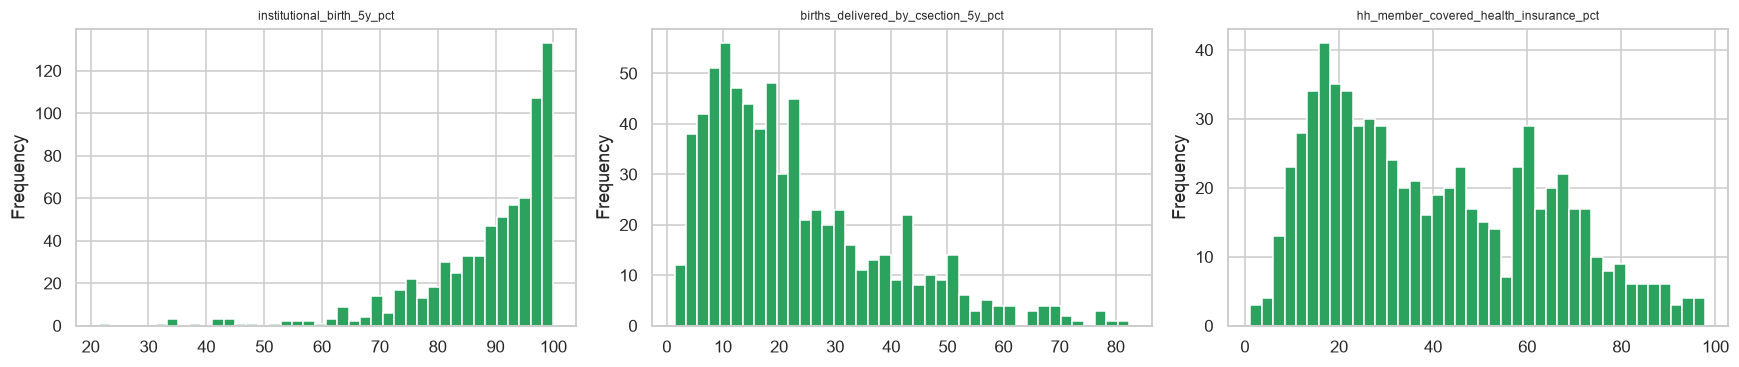

Full NFHS indicator correlation matrix computed: (107, 107)


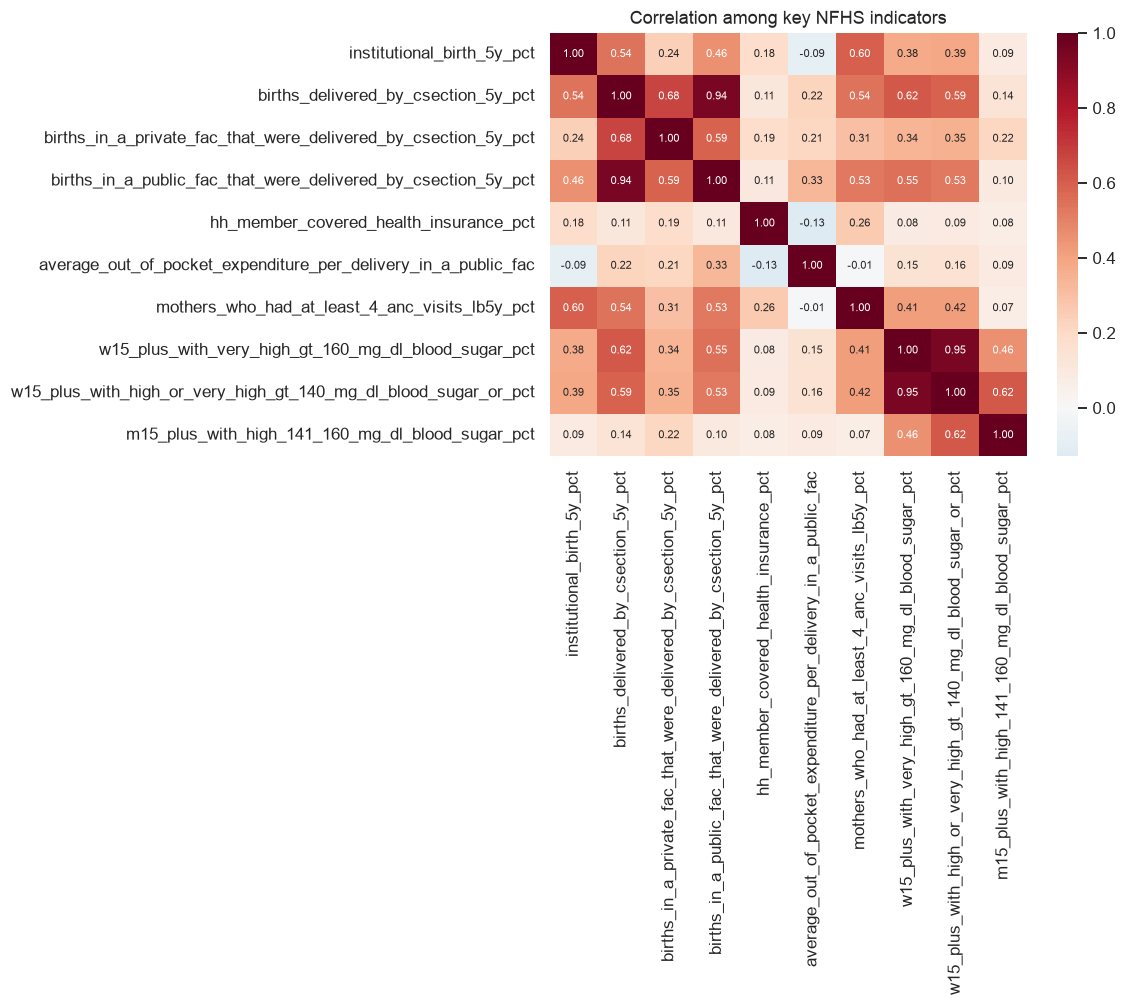

In [53]:
KEY_NFHS = ['institutional_birth_5y_pct','births_delivered_by_csection_5y_pct','births_in_a_private_fac_that_were_delivered_by_csection_5y_pct',
            'births_in_a_public_fac_that_were_delivered_by_csection_5y_pct','hh_member_covered_health_insurance_pct',
            'average_out_of_pocket_expenditure_per_delivery_in_a_public_fac','mothers_who_had_at_least_4_anc_visits_lb5y_pct']
KEY_NFHS += [c for c in nf.columns if re.search(r'blood_sugar|high_bp_sys_gte_140', c)][:3]
KEY_NFHS = [c for c in KEY_NFHS if c in nf.columns]
display(nf[KEY_NFHS].describe().T.round(1))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, c in zip(axes, KEY_NFHS[:2] + ['hh_member_covered_health_insurance_pct']):
    nf[c].plot.hist(bins=40, ax=ax, color='#2ca25f'); ax.set_title(c, fontsize=8)
plt.tight_layout(); plt.show()
corr_nf = nf[ind].corr()
print('Full NFHS indicator correlation matrix computed:', corr_nf.shape)
fig, ax = plt.subplots(figsize=(7, 5)); sns.heatmap(nf[KEY_NFHS].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size':7})
ax.set_title('Correlation among key NFHS indicators'); plt.tight_layout(); plt.show()

## 17. Cross-dataset joins: facility → PIN → district → NFHS

In [54]:
def norm_d(s): return re.sub(r'[^a-z]', '', str(s).lower())
NF_STATE_FIX = {'MAHARASTRA':'MAHARASHTRA','NCT OF DELHI':'DELHI','JAMMU & KASHMIR':'JAMMU AND KASHMIR',
                'ANDAMAN & NICOBAR ISLANDS':'ANDAMAN AND NICOBAR ISLANDS',
                'DADRA AND NAGAR HAVELI & DAMAN AND DIU':'DADRA AND NAGAR HAVELI AND DAMAN AND DIU'}
nf['state_key'] = nf.state_ut.str.upper().replace(NF_STATE_FIX)
nf['dkey'] = nf.state_key + '|' + nf.district_name.map(norm_d)
pin_dist_keys = (pin.dropna(subset=['district','statename']).assign(dkey=lambda d: d.statename + '|' + d.district.map(norm_d))
                 [['dkey']].drop_duplicates())
print('NFHS state keys not in India Post:', sorted(set(nf.state_key) - set(CANON)))
print(f'NFHS districts matched to an India Post district by exact normalised name: {nf.dkey.isin(pin_dist_keys.dkey).sum()} / {len(nf)}')
print('Unmatched examples (renamed/new districts, spelling):', nf.loc[~nf.dkey.isin(pin_dist_keys.dkey), ['district_name','state_ut']].head(12).values.tolist())

fac['dkey'] = fac.pin_state + '|' + fac.pin_district.map(norm_d)
fac_d = fac.dkey.value_counts()
print(f'\nFacilities mapped to a district via PIN: {fac.dkey.notna().sum():,}; distinct districts with >=1 facility: {fac_d.size}')
print(f'India Post districts: {pin_dist_keys.dkey.nunique()} -> districts with ZERO facilities in dataset: {pin_dist_keys.dkey.nunique() - fac_d.size}')
print('Top districts by facility count:'); print(fac_d.head(12).to_dict())

NFHS state keys not in India Post: ['DADRA AND NAGAR HAVELI AND DAMAN AND DIU']
NFHS districts matched to an India Post district by exact normalised name: 611 / 706
Unmatched examples (renamed/new districts, spelling): [['North & Middle Andaman', 'Andaman & Nicobar Islands'], ['South Andaman', 'Andaman & Nicobar Islands'], ['Visakhapatnam', 'Andhra Pradesh'], ['Sri Potti Sriramulu Nello', 'Andhra Pradesh'], ['Morigaon', 'Assam'], ['Kamrup Metropolitan', 'Assam'], ['Purba Champaran', 'Bihar'], ['Koriya', 'Chhattisgarh'], ['Kabeerdham', 'Chhattisgarh'], ['Uttar Bastar Kanker', 'Chhattisgarh'], ['Kodagaon', 'Chhattisgarh'], ['Diu', 'Dadra and Nagar Haveli & Daman and Diu']]

Facilities mapped to a district via PIN: 9,700; distinct districts with >=1 facility: 553
India Post districts: 754 -> districts with ZERO facilities in dataset: 201
Top districts by facility count:
{'MAHARASHTRA|pune': 328, 'GUJARAT|ahmadabad': 324, 'KARNATAKA|bengaluruurban': 294, 'TAMIL NADU|chennai': 285, 'MAHARAS

NFHS districts by # facilities in dataset:
{Interval(-1, 0, closed='right'): 246, Interval(0, 2, closed='right'): 155, Interval(2, 5, closed='right'): 91, Interval(5, 20, closed='right'): 123, Interval(20, 100, closed='right'): 74, Interval(100, 5000, closed='right'): 17}


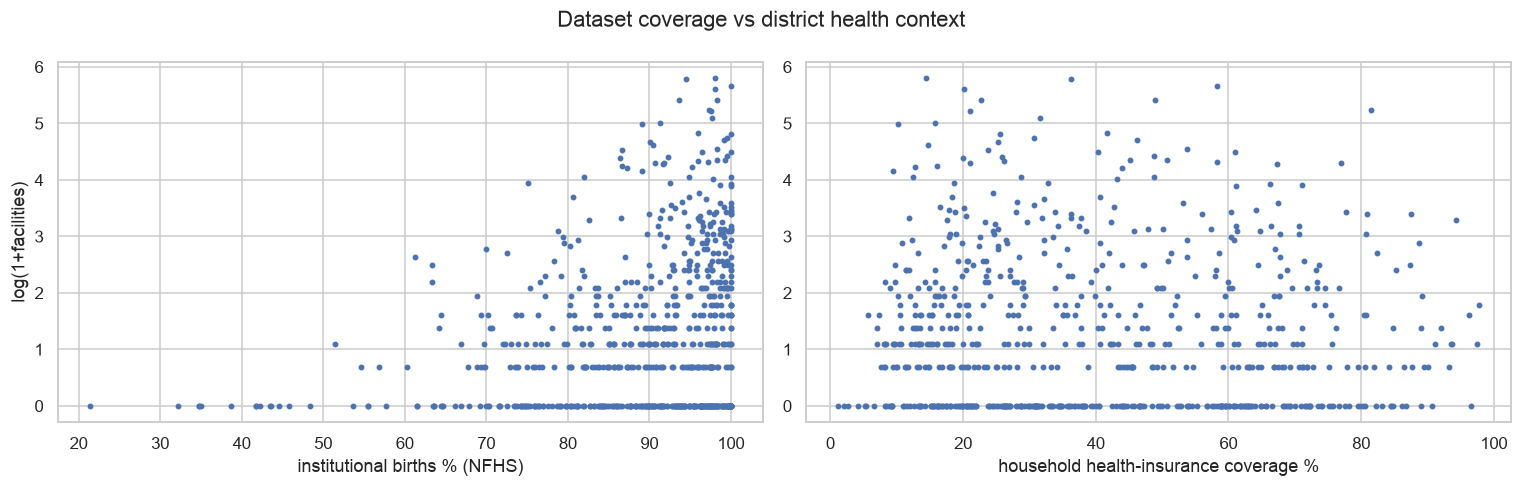

Spearman(facility count, NFHS indicator):
births_in_a_private_fac_that_were_delivered_by_csection_5y_pct    -0.09
average_out_of_pocket_expenditure_per_delivery_in_a_public_fac    -0.08
hh_member_covered_health_insurance_pct                            -0.03
m15_plus_with_high_141_160_mg_dl_blood_sugar_pct                   0.03
mothers_who_had_at_least_4_anc_visits_lb5y_pct                     0.17
births_in_a_public_fac_that_were_delivered_by_csection_5y_pct      0.20
institutional_birth_5y_pct                                         0.29
w15_plus_with_high_or_very_high_gt_140_mg_dl_blood_sugar_or_pct    0.29
births_delivered_by_csection_5y_pct                                0.31
w15_plus_with_very_high_gt_160_mg_dl_blood_sugar_pct               0.33

Districts with the highest NFHS C-section rates but NO facility with >=2-field C-section evidence:


,district_name,state_ut,births_delivered_by_csection_5y_pct,n_facilities
dkey,,,,
TELANGANA|karimnagar,Karimnagar,Telangana,82.4,14.0
TELANGANA|jangoan,Jangoan,Telangana,79.1,0.0
TELANGANA|nirmal,Nirmal,Telangana,77.3,7.0
TELANGANA|rajannasircilla,Rajanna Sircilla,Telangana,77.2,1.0
TELANGANA|suryapet,Suryapet,Telangana,77.0,1.0
TELANGANA|mahabubabad,Mahabubabad,Telangana,74.0,0.0
TELANGANA|warangalrural,Warangal Rural,Telangana,71.8,0.0
TELANGANA|peddapalli,Peddapalli,Telangana,71.6,1.0


In [55]:
nfj = nf.set_index('dkey')
nfj['n_facilities'] = fac_d.reindex(nfj.index).fillna(0)
nfj['n_hospitals'] = fac[fac.facilityTypeId=='hospital'].dkey.value_counts().reindex(nfj.index).fillna(0)
nfj['n_csection_claims'] = fac[strong['c_section']].dkey.value_counts().reindex(nfj.index).fillna(0)
nfj['n_dialysis_claims'] = fac[strong['dialysis']].dkey.value_counts().reindex(nfj.index).fillna(0)
print('NFHS districts by # facilities in dataset:'); print(pd.cut(nfj.n_facilities, [-1,0,2,5,20,100,5000]).value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(nfj.institutional_birth_5y_pct, np.log1p(nfj.n_facilities), s=8); axes[0].set_xlabel('institutional births % (NFHS)'); axes[0].set_ylabel('log(1+facilities)')
axes[1].scatter(nfj.hh_member_covered_health_insurance_pct, np.log1p(nfj.n_facilities), s=8); axes[1].set_xlabel('household health-insurance coverage %')
plt.suptitle('Dataset coverage vs district health context'); plt.tight_layout(); plt.show()
print('Spearman(facility count, NFHS indicator):')
print(nfj[KEY_NFHS].corrwith(nfj.n_facilities, method='spearman').round(2).sort_values().to_string())
print('\nDistricts with the highest NFHS C-section rates but NO facility with >=2-field C-section evidence:')
display(nfj[nfj.n_csection_claims == 0].sort_values('births_delivered_by_csection_5y_pct', ascending=False)[['district_name','state_ut','births_delivered_by_csection_5y_pct','n_facilities']].head(8))

In [56]:
# State-level: facilities per NFHS-surveyed household (proxy for representation)
st_fac = fac.state_final.value_counts()
st_nf = nf.groupby('state_key').households_surveyed.sum()
rep = pd.DataFrame({'facilities': st_fac, 'nfhs_districts': nf.state_key.value_counts()}).fillna(0)
rep['facilities_per_district'] = (rep.facilities / rep.nfhs_districts.replace(0, np.nan)).round(1)
rep.sort_values('facilities_per_district')

,facilities,nfhs_districts,facilities_per_district
LADAKH,0.0,2.0,0.0
LAKSHADWEEP,0.0,1.0,0.0
DADRA AND NAGAR HAVELI AND DAMAN AND DIU,0.0,3.0,0.0
ARUNACHAL PRADESH,3.0,20.0,0.2
MIZORAM,3.0,8.0,0.4
NAGALAND,6.0,11.0,0.5
ANDAMAN AND NICOBAR ISLANDS,2.0,3.0,0.7
SIKKIM,4.0,4.0,1.0
TRIPURA,9.0,8.0,1.1
MEGHALAYA,14.0,11.0,1.3


## 18. Per-facility completeness / evidence score

A simple transparent score – share of evidence-bearing attributes present – to show how unevenly informative records are. (Not a ranking model; a profiling aid.)

,% facilities
has_capacity,25.0
has_doctors,36.2
has_year,47.7
desc_>100_chars,56.2
has_equipment,71.2
coords_consistent,77.2
has_official_site,83.9
has_procedure,88.5
has_phone,95.0
has_valid_pin,97.1


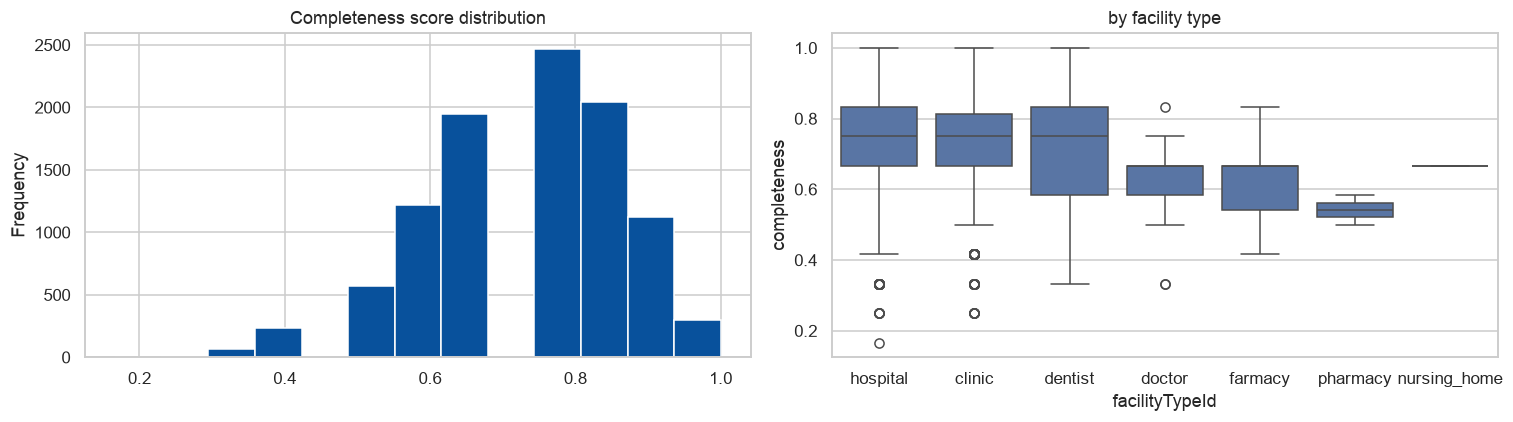

Mean completeness by state (top/bottom):
                   mean  size
state_final                  
HIMACHAL PRADESH   0.69    38
JAMMU AND KASHMIR  0.70    70
ASSAM              0.71   119
GUJARAT            0.72   996
UTTAR PRADESH      0.72   953
CHANDIGARH         0.75    47
TELANGANA          0.75   432
KERALA             0.75   522
DELHI              0.75   353
GOA                0.76    35


In [57]:
EVID = {'has_specialties': ~nofo.specialties, 'has_procedure': ~nofo.procedure,
        'has_equipment': ~nofo.equipment, 'has_capability': ~nofo.capability,
        'has_doctors': fac.numberDoctors > 0, 'has_capacity': fac.capacity > 0, 'has_year': fac.yearEstablished > 1800,
        'has_valid_pin': fac.pin_in_directory, 'coords_consistent': fac.km_to_pin <= 25,
        'has_official_site': fac.officialWebsite.notna(), 'has_phone': fac.officialPhone.notna(),
        'desc_>100_chars': fac.description.str.len() > 100}
E = pd.DataFrame(EVID).fillna(False)
fac['completeness'] = E.mean(axis=1)
display(E.mean().mul(100).round(1).sort_values().to_frame('% facilities'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fac.completeness.plot.hist(bins=13, ax=axes[0], color='#08519c'); axes[0].set_title('Completeness score distribution')
sns.boxplot(x=fac.facilityTypeId, y=fac.completeness, ax=axes[1], order=fac.facilityTypeId.value_counts().index); axes[1].set_title('by facility type')
plt.tight_layout(); plt.show()
print('Mean completeness by state (top/bottom):')
cs = fac.groupby('state_final').completeness.agg(['mean','size']).query('size >= 20').sort_values('mean')
print(pd.concat([cs.head(5), cs.tail(5)]).round(2).to_string())

## 19. Key findings & implications for the build

In [58]:
# Numbers referenced in the findings below (computed, not hard-coded)
summary = {
 'raw lines parsed': len(raw), 'junk fragment rows': int((~is_valid).sum()), 'valid facilities': len(fac),
 'truncated records': int(truncated.sum()),
 'distinct raw state strings': int(fac.address_stateOrRegion.nunique()),
 'state vs PIN conflicts': int(fac.state_pin_conflict.sum()),
 'coords >50km from PIN': int((fac.km_to_pin > 50).sum()),
 'coords outside India': int((fac.latitude.notna() & ~in_india(fac.latitude, fac.longitude)).sum()),
 'records with any list at 50 cap': int(flags.any_list_hit_50_cap.sum()),
 'equipment null/empty/blank-only %': round(float(nofo.equipment.mean()*100), 1),
 'top-5 state share %': round(float(sc.head(5).sum()/len(fac)*100), 1),
 'districts with zero facilities': int(pin_dist_keys.dkey.nunique() - fac_d.size),
 'NFHS suppressed cells': int(star.values.sum()), 'NFHS low-reliability cells': int(paren.values.sum()),
}
pd.Series(summary).to_frame('value')

,value
raw lines parsed,10088.0
junk fragment rows,88.0
valid facilities,9989.0
truncated records,30.0
distinct raw state strings,234.0
state vs PIN conflicts,65.0
coords >50km from PIN,1562.0
coords outside India,6.0
records with any list at 50 cap,3220.0
equipment null/empty/blank-only %,28.8


### A. File & record integrity
1. **The CSV is non-standard**: quotes are backslash-escaped, so a default reader crashes. Load with `escapechar='\\'`. On Databricks use `spark.read.option("escape","\\").option("multiLine",True)`.
2. **88 junk rows** are pieces of descriptions that contained raw newlines. Filter on a UUID-shaped `unique_id`.
3. **11 exact-duplicate rows** mean `unique_id` is not unique as shipped. After de-duplication there are **9,989 facilities**, not 10,000.
4. **30 truncated records** have a description, but every field after it is lost (no offerings, coordinates or sources). They should never be recommended with confidence.

### B. Missingness: what is actually there
5. Missing values come in three forms: the literal `null`, empty strings, and empty lists. Lists can be `[]`, or `[""]` with only blank items. Counting all three, **equipment has no information for ~29% of facilities** and procedure for ~11%. The brief's 77% / 92.5% figures only count `[]`.
6. **Scale fields are sparse**: capacity (beds) is present for 25%, doctors for 36% and year for 48%. They are missing far more often for clinics and dentists (97–99% have no capacity). Missingness depends on facility type, so it is not random. Never impute and then present the result as fact.
7. Contact fields go missing together (phone with officialPhone, email with website), and so do the social metrics. These are *web-presence* signals.
8. Dead columns: `countries` (100% null), `acceptsVolunteers` (99.8%), `area` (98.8%, unit unknown). Constant columns: `organization_type`, `address_country(Code)` and `source`. `content_table_id` duplicates `source_content_id`, and `coordinates` duplicates lat/long.

### C. Evidence fields: rich but noisy
9. **Every list is capped at 50 items. About 32% of facilities have at least one list at the cap**, so those lists were cut off. Capped records have twice as many coordinate conflicts (24% vs 12%) and are the most likely to be **merges of several facilities**. The Aravind record and the Fortis equipment list show this clearly.
10. Lists contain **blank items and LLM placeholder text** ("No specific medical equipment listed for … in the provided content"). This text has to be filtered out or it will look like evidence.
11. `specialties` uses a camelCase vocabulary, but `internalMedicine` appears on 68% of facilities (close to a default) and specialties repeat within a list (about 55% duplicates). Specialty codes and free text often disagree: 826 facilities list `nephrology` with no dialysis text, and 293 mention dialysis without the specialty. **Concrete equipment or procedure sentences are stronger evidence than specialty tags.**
12. Free-text items are very varied: 34k distinct equipment strings and 165k distinct capability strings, with spelling variants such as "wheelchair-accessible" vs "wheel chair accessible". Matching needs keyword/regex or embedding search with synonym lists, not exact-match lookups.

### D. Location: the biggest trust problem
13. `address_stateOrRegion` has **234 distinct strings for 36 states/UTs**. These include typos (Tamilnadu, Telengana, Orissa, U.p.) and **284 rows with a city in the state field**. 272 of those can be fixed from the PIN.
14. 97.8% of PIN codes are valid India Post PINs. **65 records give a state that contradicts their own PIN**: 25 are AP/Telangana confusion left over from the 2014 split, and the rest are true conflicts.
15. **16% of facilities have coordinates more than 50 km from their own PIN centroid** (12.7% more than 100 km, 2% more than 500 km). Six are outside India. PIN centroids are reliable (a median of 2.4 km spread), so these are real conflicts. **Distance-based ranking should check coordinates against the PIN/city and lower confidence when they disagree.**
16. Coverage is heavily skewed: **the top 5 states hold 50% of facilities**, while Ladakh, Lakshadweep and DNH-DD have none. 201 of 754 India Post districts have zero facilities, and the North-East averages under 1.5 per district. "No result nearby" often means *missing from the dataset*, not *no care available*, and the build should say so.
17. City names have variants (Bangalore/Bengaluru, Gurgaon/Gurugram, Trivandrum/Thiruvananthapuram). Geocode location input through the PIN directory, not by string match.

### E. Numbers: treat them as claims
18. Implausible values include 200,000 beds, 15,000 doctors, establishment years of 0, 7 and 15, and 72 facilities with "1 doctor but at least 100 beds". `numberDoctors=1` is the most common value (1,194 records). It probably means one *named* doctor was found, not the staff size.
19. **Value heaping**: 71% of bed counts (10 or more) are multiples of 10, so they are estimates. Bed counts are only a rough size signal.
20. Size signals correlate with *web footprint* (number of URLs, websites and specialties; ρ≈0.8). A facility that looks bigger may simply be better covered online. **Normalise or cap evidence-volume features so ranking does not just reward an SEO footprint.**
21. Follower counts belong to brand or chain pages (identical 4.7M values on unrelated hospitals). They measure popularity, not quality or capability.

### F. Provenance
22. Each record cites a median of 10 source URLs across 6 domains. Only 47% include the facility's own website, and about 1,000 have a `.gov.in` / `nic.in` source. These are high-trust sources worth weighting, such as empanelment lists.
23. 363 emails are the Cloudflare placeholder `[email protected]`, and 62% of emails use free-mail providers.

### G. Service claims (challenge services)
24. Evidence depth varies a lot by service. **79% of C-section claims and 73% of ventilator claims come from a single field**, and only 4 facilities mention C-section in 3 or more fields. Common services such as obstetrics, emergency, ICU and dialysis have hundreds of facilities with evidence in 3 or more fields. Low depth means **wording uncertainty**: "obstetrics + operating theatre" may imply C-section without saying it.
25. Some claims contradict the facility type: 567 clinics or dentists claim heavy services (ICU, dialysis, cardiac surgery). These are often text merged in from a parent hospital or aggregator.

### H. Helper datasets
26. **India Post directory**: 7% of offices lack coordinates and about 1,600 have garbage coordinates, so filter to India's bounding box and use the median per PIN. 52 PINs span two states and 1,258 span two districts. It is the best tool for turning PIN/city input into coordinates and for validating facility locations.
27. **NFHS-5**: `*` means suppressed (n<25) and `(x)` means low reliability (n 25–49). Together they cover about 12% of cells. Parse and flag them; do not treat them as plain numbers. Some state names differ (Maharastra, NCT of Delhi, J&K). District names repeat across states (Aurangabad, Bilaspur…), so join on state plus district. 611 of 706 districts match India Post by name and the rest need a crosswalk (renamed or new districts).
28. Facility count per district correlates with institutional birth and C-section rates (ρ≈0.3). The dataset is denser where care already exists, so NFHS can highlight **high-need, low-coverage districts**, for example Telangana districts with C-section rates above 70% and no C-section evidence.

### Implications for the recommender
- **Clean first**: escape-aware parse, drop fragments and duplicates, normalise states, validate PINs, flag truncated records.
- **Evidence score per (facility, service)**: count independent fields with a match. Weight equipment and procedure above specialty tags, give bonus weight to .gov sources and the facility's own website, and filter out placeholders.
- **Location confidence**: lower it for coordinates more than 25–50 km from the PIN, state–PIN conflicts and lists at the cap (likely merges).
- **Always show the cited text snippets and source URLs** behind each claim, and label results with a confidence level (strong / moderate / weak / unverified) instead of hiding weak matches.